<a href="https://colab.research.google.com/github/kadrikalamae-gif/bird-species-recognition-cnn/blob/main/BERN02_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Recognising bird species in citizen-science photos with small convolutional networks

Sek Huen Leung, Kadri Kalamäe · BERN02 Reproducible data science and statistical learning · 19.10.2026

# 1. Introduction

Citizen-science platforms provide large collections of wildlife photographs labelled by species, making them a potentially valuable resource for image classification. However, these photographs are not collected under controlled conditions. Images differ in resolution, lighting, background, camera and distance to the animal, and the bird may occupy only a small part of the frame. Such variation can make species recognition difficult, particularly when the training set is modest in size.

This project investigates bird-species classification using photographs from the iNaturalist Research-Grade Observations dataset accessed through GBIF. We focus on four common Northern European species: mallard (*Anas platyrhynchos*), hooded crow (*Corvus cornix*), great tit (*Parus major*) and common blackbird (*Turdus merula*). The observations are from Sweden, Norway, Denmark, Finland, Estonia, Latvia and Lithuania. After filtering for compatible image licences, the working dataset contains 2,188 observations. The labels represent community-agreed identifications rather than independent expert verification, so model performance should be understood as agreement with those labels.

After examining image dimensions and some preprocessing options, we develop a baseline convolutional neural network (CNN), investigate architectural and training choices, and compare input resolutions. We also explore transfer learning using frozen ResNet50 features and logistic regression to assess the potential benefits of pretrained representations on this relatively small dataset. The main experimental part then examines how image representation, preprocessing, and input resolution affect CNN performance. Four controlled experiments investigate (1) the role of colour information by comparing RGB and grayscale inputs, including mismatches between training and evaluation representations; (2) the effect of additional random brightness and contrast augmentation during training; (3) the impact of deterministic contrast-enhancement methods at a fixed resolution; and (4) how the performance of these enhancement methods varies across different input resolutions. Using photographer-grouped cross-validation, we compare model configurations based primarily on macro-F1. Finally, five configurations selected from the cross-validation results, including the original RGB baseline, are evaluated on an independent held-out test set to assess their performance on photographs from previously unseen photographers.

The evaluation design accounts for repeated contributions by individual photographers. Images are divided into a training set and an independent held-out test set, with photographer groups kept separate. Model configurations are compared using grouped cross-validation on the development data. Macro-F1 is the primary metric because it gives each species equal weight, while accuracy, balanced accuracy and species-level results provide complementary views. The held-out test set is used to evaluate the selected models, while the configurations in the main experiments are compared using training-only cross-validation. Test-set performance is not used as a model-selection criterion in Experiments 1–4. Since the number of grouped folds and training seeds is limited, differences are interpreted descriptively rather than as formal evidence of statistical significance.

The remaining sections describe the data and splitting procedure, document some preprocessing choices and model evaluation, present the controlled experiments and held-out test results, and conclude with a reflection on FAIR principles.

First, we import standard data manipulation and machine learning libraries.

In [ ]:
import os

os.environ["TF_DETERMINISTIC_OPS"] = "1"
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import time
import numpy as np
import pandas as pd
import math
import gdown
from pathlib import Path
import sys
import zipfile
import shutil
import matplotlib.pyplot as plt
from PIL import Image
import seaborn as sns
import tensorflow as tf
import keras
from tensorflow import keras
from keras import layers
from keras.applications.resnet50 import ResNet50, preprocess_input
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sklearn.metrics import f1_score, balanced_accuracy_score, ConfusionMatrixDisplay, accuracy_score, confusion_matrix, classification_report
import torch
from torchvision import models
import cv2
import gc

keras.utils.set_random_seed(1234)
tf.config.experimental.enable_op_determinism()

The Python and package versions used for the experiments are reported below. As Google Colab's environment may change, exact reproduction may require adjusting package versions.

In [ ]:
from importlib.metadata import version, PackageNotFoundError
import platform

print("Python:", platform.python_version())

packages = [
    "numpy",
    "pandas",
    "gdown",
    "matplotlib",
    "Pillow",
    "tensorflow",
    "keras",
    "scikit-learn",
    "torch",
    "torchvision",
    "opencv-python",
]

for package in packages:
    try:
        print(f"{package}=={version(package)}")
    except PackageNotFoundError:
        print(f"{package}: not installed")

Python: 3.13.15
numpy==2.1.3
pandas==2.2.3
gdown==5.2.2
matplotlib==3.10.0
Pillow==11.3.0
tensorflow==2.21.0
keras==3.13.2
scikit-learn==1.6.1
torch==2.11.0+cu130
torchvision==0.26.0+cu130
opencv-python==5.0.0.93


# 2. Data and Exploratory Analysis

The photos and their labels come from the iNaturalist Research-Grade
Observations data set, which we downloaded through GBIF
(GBIF.org (10/15/2026) GBIF Occurrence Download https://doi.org/10.15468/dl.pfd9ab). Research grade
means that the community has agreed on the species. We used only human observations
with still images, the class Aves, the four species (mallard, hooded crow, great tit, common blackbird), and the countries
Sweden, Estonia, Norway, Denmark, Finland, Lithuania and Latvia.

Each photo has its own license. We kept only CC0, CC BY and CC BY-SA
photos. The photographer, license and URL of every photo are stored in `metadata.csv`.

The labels are community consensus, not expert ground truth, and they can be influenced by iNaturalist's own suggestion model. Accuracy here therefore
measures agreement with iNaturalist's consensus.

To work with the images efficiently within Google Colab, we considered two main storage approaches:
1. Unpacking the images directly into Colab's local storage, which means all files are lost when the session ends and must be re-downloaded every time.
2. Storing and extracting the dataset archive via Google Drive.

We chose the second option because it ensures long-term persistence across sessions and provides a much faster, more reliable workflow for repeated image loading and model training.




In [ ]:
GBIF_URL = "https://api.gbif.org/v1/occurrence/download/request/0028373-260928105237408.zip"
GBIF_DOI = "https://doi.org/10.15468/dl.pfd9ab"
ACCESSED = "10/15/2026"
print("GBIF.org (" + ACCESSED + ") GBIF Occurrence Download " + GBIF_DOI)

GBIF.org (10/15/2026) GBIF Occurrence Download https://doi.org/10.15468/dl.pfd9ab


This notebook is designed for Google Colab. The setup cell installs gdown, downloads the dataset from a shared Google Drive link, and extracts it into the runtime. No manual download or Google Drive mounting is required.

Run the cells in order. Colab's runtime storage is temporary, so the dataset may need to be downloaded again after a runtime reset.

In [ ]:

%pip -q install gdown

# --- Google Drive shared link -----------------------------------------
DRIVE_LINK = "https://drive.google.com/file/d/1fr87Y-_XbghY2pdKQq9XSXU_8I8rV0R2/view?usp=sharing"

GBIF_DOI = "https://doi.org/10.15468/dl.pfd9ab"

# --- Species ----------------------------------------------------------
SPECIES = [
    "Anas platyrhynchos",
    "Corvus cornix",
    "Parus major",
    "Turdus merula"
]

# --- Paths ------------------------------------------------------------
ROOT = Path("/content")
DATA_DIR = ROOT / "gbif_4species"
IMG_DIR = DATA_DIR / "bird_images"
META_PATH = DATA_DIR / "metadata.csv"
PROBLEM_PATH = DATA_DIR / "malformed_multimedia_rows.csv"
ZIP_PATH = ROOT / "bird_dataset_4species.zip"

# Set True when replacing an existing dataset
FORCE_DOWNLOAD = False

# --- Check whether dataset is ready ----------------------------------
def data_ready():
    if not IMG_DIR.is_dir() or not META_PATH.is_file():
        return False

    try:
        df = pd.read_csv(META_PATH, dtype={"gbifID": str})

        return (
            len(df) > 0
            and set(df["species"]) == set(SPECIES)
            and "fold" not in df.columns
            and df["file"].notna().all()
            and all((IMG_DIR / f).is_file() for f in df["file"])
        )

    except (OSError, ValueError, KeyError, TypeError):
        return False


# --- Download and extract --------------------------------------------
if FORCE_DOWNLOAD or not data_ready():

    if DATA_DIR.exists():
        shutil.rmtree(DATA_DIR)

    ZIP_PATH.unlink(missing_ok=True)

    print("Downloading dataset from Google Drive...")

    result = gdown.download(
        url=DRIVE_LINK,
        output=str(ZIP_PATH),
        fuzzy=True,
        quiet=False
    )

    if result is None or not zipfile.is_zipfile(ZIP_PATH):
        raise RuntimeError("Download failed. Check the shared link.")

    print("Extracting dataset...")

    DATA_DIR.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall(DATA_DIR)

else:
    print("Dataset already exists. Skipping download.")


# --- Load metadata ----------------------------------------------------
all_data = pd.read_csv(
    META_PATH,
    dtype={"gbifID": str}
)


# --- Verify dataset ---------------------------------------------------
assert set(all_data["species"]) == set(SPECIES), \
    "Dataset does not contain exactly the expected four species!"

assert all_data["file"].notna().all(), \
    "Some image filenames are missing!"

assert all_data["gbifID"].is_unique, \
    "Duplicate GBIF occurrences found!"

missing = sum(
    not (IMG_DIR / f).is_file()
    for f in all_data["file"]
)

assert missing == 0, f"{missing} images are missing!"


# --- Check malformed multimedia records ------------------------------
if PROBLEM_PATH.is_file():
    malformed = pd.read_csv(PROBLEM_PATH)

    print("\nMalformed multimedia records:", len(malformed))
    print("These records are retained for later inspection.")

else:
    print("\nNo separate malformed multimedia file found.")

if "media_parse_issue" in all_data.columns:
    n_flagged = all_data["media_parse_issue"].notna().sum()
    print("Selected images with flagged metadata:", n_flagged)


# --- Summary ----------------------------------------------------------
print("\nDataset ready!")
print("GBIF DOI:", GBIF_DOI)
print("Data folder:", IMG_DIR.resolve())
print("Observations:", len(all_data))
print("Species:", all_data["species"].nunique())

Downloading...
From (original): https://drive.google.com/uc?id=1fr87Y-_XbghY2pdKQq9XSXU_8I8rV0R2
From (redirected): https://drive.google.com/uc?id=1fr87Y-_XbghY2pdKQq9XSXU_8I8rV0R2&confirm=t&uuid=b6fee283-bd39-4dbf-a0ab-d008361518ae
To: /content/bird_dataset_4species.zip
100%|██████████| 310M/310M [00:03<00:00, 103MB/s]


Extracting dataset...

No separate malformed multimedia file found.

Dataset ready!
GBIF DOI: https://doi.org/10.15468/dl.pfd9ab
Data folder: /content/gbif_4species/bird_images
Observations: 2438
Species: 4


In [ ]:
# Filter metadata to keep only CC0, CC BY, and CC BY-SA licenses
allowed_licenses = [
    "http://creativecommons.org/publicdomain/zero/1.0/",
    "http://creativecommons.org/licenses/by/4.0/",
    "http://creativecommons.org/licenses/by-sa/4.0/"
]

all_data = all_data[all_data["license"].isin(allowed_licenses)].copy()

print(f"Filtered dataset to {len(all_data)} rows with compatible open licenses.")
print(all_data["license"].value_counts())

short = ["mallard", "hooded crow", "great tit", "common blackbird"]
species_to_short = dict(zip(SPECIES, short))

print("\nCLASS DISTRIBUTION")
dist_short = all_data["species"].map(species_to_short).value_counts()
print(dist_short)

print("\nCOUNTRY DISTRIBUTION")
print(all_data["countryCode"].value_counts())

Filtered dataset to 2188 rows with compatible open licenses.
license
http://creativecommons.org/publicdomain/zero/1.0/    1790
http://creativecommons.org/licenses/by/4.0/           349
http://creativecommons.org/licenses/by-sa/4.0/         49
Name: count, dtype: int64

CLASS DISTRIBUTION
species
mallard             655
hooded crow         537
great tit           533
common blackbird    463
Name: count, dtype: int64

COUNTRY DISTRIBUTION
countryCode
SE    559
EE    505
NO    432
DK    320
FI    304
LT     41
LV     27
Name: count, dtype: int64


The filtered dataset contains 2,188 observations across our four target species. The class distribution is fairly balanced, led by mallards (655 photos), followed by hooded crows (537), great tits (533), and common blackbirds (463). Geographically, the observations span across Northern and Baltic European countries, with Sweden (SE) and Estonia (EE) contributing the highest volume of records.

Looking at the timeline below, the number of observations starts growing fast around 2019. One can spot a few shifts among the species over the years. Great tits peaked 2017-2020, mallards were more protographed than other three species in 2021-2023, and common blackbirds show up more than others in the most recent years. The overall balance between species is close enough that we don't need to tweak our modeling setup for it. Still, it's worth keeping in mind that these are crowdsourced photos taken with different phones and cameras over a long period. Because of that, background clutter, lighting, and photo quality will vary across the dataset.

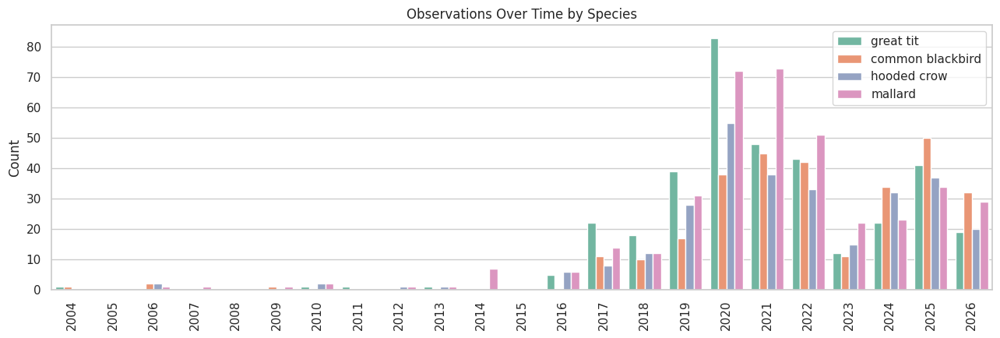

In [ ]:
sns.set_theme(style="whitegrid")
plt.rcParams.update({'figure.autolayout': True})

all_data["year"] = pd.to_datetime(
    all_data["eventDate"], errors="coerce"
).dt.year

plot_df = all_data.dropna(subset=["year"]).copy()
plot_df["year"] = plot_df["year"].astype(int)
plot_df["short_species"] = plot_df["species"].map(species_to_short)

year_order = range(plot_df["year"].min(), plot_df["year"].max() + 1)

plt.figure(figsize=(13, 4.5))
sns.countplot(
    data=plot_df,
    x="year",
    hue="short_species",
    order=year_order,
    palette="Set2"
)

plt.title("Observations Over Time by Species")
plt.xlabel("")
plt.ylabel("Count")
plt.xticks(rotation=90)
plt.legend(title="", frameon=True)
plt.tight_layout()
plt.show()

Next, we want to see how many different photographers contributed and whether a small group of active users accounts for the majority of the observations. The dataset includes photos from 192 photographers, but the contributions are heavily concentrated. Just 5 photographers account for nearly half (49%) of all observations in the dataset. This heavy imbalance makes grouped splitting essential: if we used standard random splitting, images from the same photographer with their distinct camera settings, favorite locations, or processing style would leak into both training and test sets.

In [ ]:
by_creator = all_data.groupby("creator")["gbifID"].nunique().sort_values(ascending=False)
print("photographers:", len(by_creator))
print(by_creator.head(10))
print("share of observations from the top 5 photographers:",
      round(by_creator.head(5).sum() / all_data["gbifID"].nunique(), 2))

photographers: 192
creator
Nicolás Tamargo        350
Wouter Koch            301
Jens Ullenius          235
OlleHanna              100
Yehor Yatsiuk           93
Nikolay Volik           73
Alex Sosnovshchenko     61
o2k                     50
Margit Kildevang        50
Donald Hobern           36
Name: gbifID, dtype: int64
share of observations from the top 5 photographers: 0.49


# 3. Data Splitting and Image Resizing

## 3.1 Development and Held-Out Test Sets

To properly evaluate our models and prevent data leakage, we divide the dataset into two parts: an independent test set held out for final evaluation, and a training set used for model development and tuning. Because our dataset contains multiple photos taken by the same photographers (who may have distinct camera setups, styles, or locations) we use `StratifiedGroupKFold`. This ensures that photographers in the training set do not appear in the test set and the species proportions remain steady across splits. We also set up a 5-fold cross-validation scheme within the training set for model selection and validation, applying the same group-splitting logic so that photographers never overlap between the different training folds either.

In [ ]:
RANDOM_SEED = 1234
N_FOLDS = 5

# Split into training and held-out test data

outer_split = StratifiedGroupKFold(
    n_splits=6,
    shuffle=True,
    random_state=RANDOM_SEED
)

X = all_data["file"]
y = all_data["species"]
groups = all_data["creator"] # Grouping by photographer

train_idx, test_idx = next(
    outer_split.split(X, y, groups)
)

train_df = all_data.iloc[train_idx].reset_index(drop=True)
test_df = all_data.iloc[test_idx].reset_index(drop=True)

# Create 5 CV folds inside training data

cv = StratifiedGroupKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=RANDOM_SEED
)

train_df["fold"] = -1

for fold, (_, val_idx) in enumerate(
    cv.split(
        train_df,
        y=train_df["species"],
        groups=train_df["creator"]
    )
):
    train_df.loc[val_idx, "fold"] = fold


# No group shared between training and test
assert set(train_df["creator"]).isdisjoint(set(test_df["creator"]))

# Every training image is assigned to a fold
assert train_df["fold"].between(0, N_FOLDS - 1).all()

# All four species must appear in both datasets
assert set(train_df["species"]) == set(SPECIES)
assert set(test_df["species"]) == set(SPECIES)

print(f"Training: {len(train_df)} ({len(train_df)/len(all_data):.1%}) | Unique photographers: {train_df['creator'].nunique()}")
print(f"Test:     {len(test_df)} ({len(test_df)/len(all_data):.1%}) | Unique photographers: {test_df['creator'].nunique()}")

# Verify class balance and zero photographer overlap
print("\nTRAIN SPECIES BALANCE:")
train_balance = train_df["species"].value_counts(normalize=True)
train_balance.index = train_balance.index.map(species_to_short)
print(train_balance)

print("\nTEST SPECIES BALANCE:")
test_balance = test_df["species"].value_counts(normalize=True)
test_balance.index = test_balance.index.map(species_to_short)
print(test_balance)

overlap = set(train_df["creator"]).intersection(set(test_df["creator"]))
print(f"\nOverlapping photographers between train and test: {len(overlap)} (should be 0)")

print("\n5-FOLD DISTRIBUTION (TRAINING ONLY):")
print(
    pd.crosstab(
        train_df["fold"],
        train_df["species"].map(species_to_short)
    ).reindex(columns=short, fill_value=0)
)

Training: 1591 (72.7%) | Unique photographers: 154
Test:     597 (27.3%) | Unique photographers: 38

TRAIN SPECIES BALANCE:
species
mallard             0.291012
great tit           0.248272
hooded crow         0.235072
common blackbird    0.225644
Name: proportion, dtype: float64

TEST SPECIES BALANCE:
species
mallard             0.321608
hooded crow         0.273032
great tit           0.231156
common blackbird    0.174204
Name: proportion, dtype: float64

Overlapping photographers between train and test: 0 (should be 0)

5-FOLD DISTRIBUTION (TRAINING ONLY):
species  mallard  hooded crow  great tit  common blackbird
fold                                                      
0             99           64         89                78
1            114           99         67               119
2             42           39         26                30
3            131          116        185               103
4             77           56         28                29


The dataset is split into 1,591 training samples (approx. 72.7%) and 597 test samples (approx. 27.3%) across 154 and 38 unique photographers, respectively. Both the training and test sets maintain a balanced distribution across all four species. The five-fold breakdown reveals substantial differences in fold size, ranging from 137 images in fold 2 to 535 images in fold 3. Species proportions also vary across folds, as the grouping constraint limits the ability to achieve exact stratification. These imbalances may contribute to variation in fold-level evaluation scores, since smaller evaluation folds provide less data and may be more sensitive to individual examples.

## 3.2 Image Inspection and Preprocessing

To better understand our dataset, we begin by taking a first look at a sample of the images we will be feeding into the model. The grid shows six randomly chosen photos per species, displayed in their original size and proportions. First, we see that the photos have different sizes and shapes. Some are landscape, some are portrait, and the pixel sizes differ. A CNN with a fully connected layer after the convolutions needs every input to have the same size, so all photos must be converted to one common square size before training. Secondly, we notice that the bird is often small or off-centre. Many photos show a distant bird (mallards on open water, a crow on a car). In some photos the labelled species is hard to find at all. This is typical for citizen-science photos, and it means that shrinking the whole photo also shrinks the bird. We expect small birds to be hard at low resolution, which is why we compare several image sizes later. Third, there is a lot of variation inside one species. For example, the mallard photos may show males, females, ducklings and groups, on water, grass and mud. Finally, the background and light vary strongly (blue sky, green grass, dark water, grey mud).

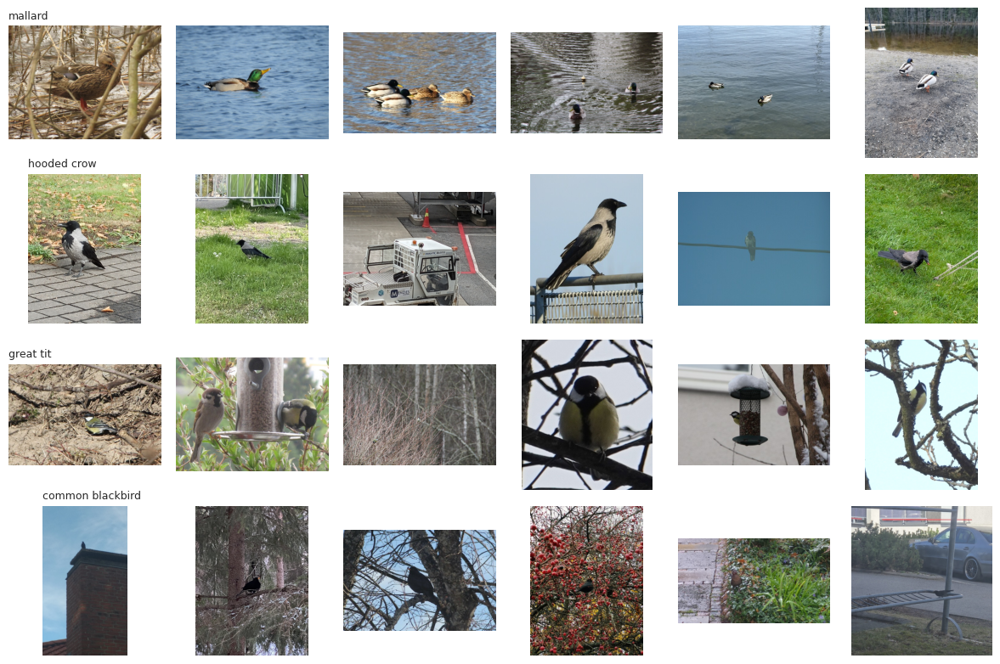

In [ ]:
fig, axs = plt.subplots(len(SPECIES), 6, figsize=(12, 2 * len(SPECIES)))
for r, (sp, short_name) in enumerate(zip(SPECIES, short)):
    rows = train_df[train_df["species"] == sp].sample(6, random_state=100)
    for c, f in enumerate(rows["file"]):
        axs[r, c].imshow(Image.open(IMG_DIR / f)); axs[r, c].axis("off")
    axs[r, 0].set_title(short_name, fontsize=9, loc="left")
plt.tight_layout()

To standardize image dimensions for model input, several options were evaluated. Direct resizing ("squashing") stretches the image to the target square size, distorting object shapes and altering proportions. Center cropping retains proportions but removes surrounding pixels, risking the loss of birds located near the edges or off-center. More complex options, such as random cropped augmentations or object detector-based cropping, require missing bounding boxes or additional pretrained models, making them unfeasible for immediate implementation. Consequently, the chosen approach is padding to a square with neutral mid-grey bars (RGB 128, 128, 128) before resizing. This method preserves the entire image and its original aspect ratio without distorting the subjects. However, a key limitation of this approach is that shrinking the whole photo also shrinks the bird itself. Without bounding boxes to enable targeted zooming, smaller birds like the great tit inevitably become even harder for the model to detect and classify compared to larger species like crows and mallards. While padding uses extra pixel space, using mid-grey ensures the added borders sit neutral in the normalized $[0, 1]$ value range and introduce no false color features to the model. We did not compare the three conversion methods experimentally, the choice is based on the argument above. The different image standardization methods are illustrated in the figure below.

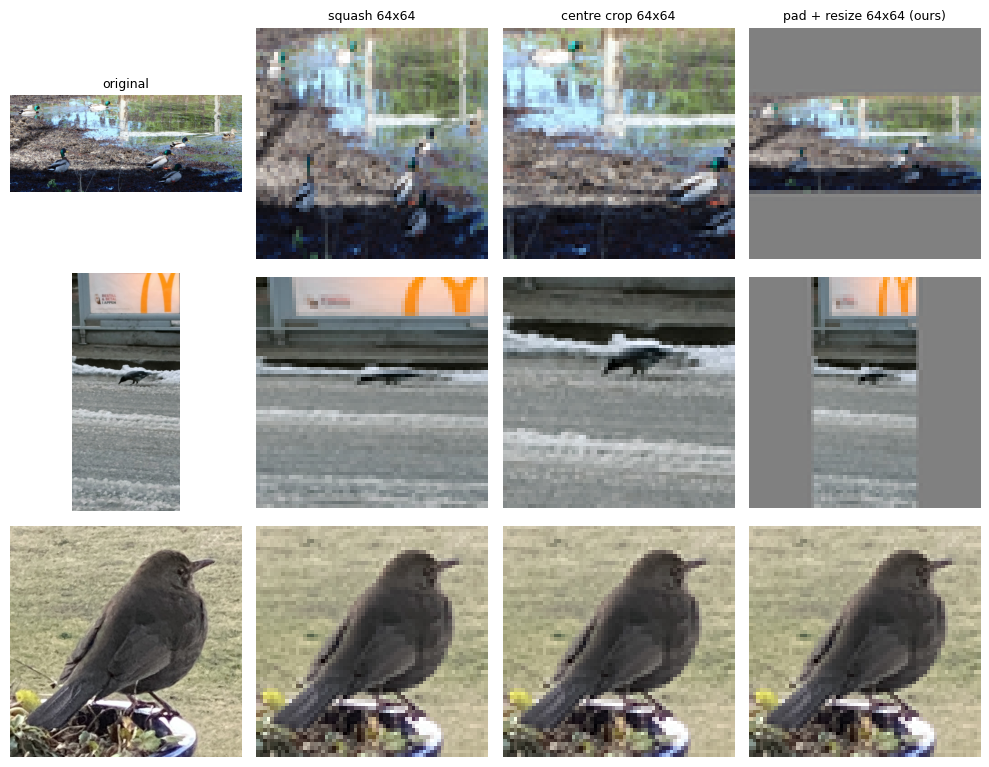

In [ ]:
def load_img(f, size=32):
    im = Image.open(IMG_DIR / f).convert("RGB")
    s = max(im.size)                                                # side of the square that fits the whole image
    canvas = Image.new("RGB", (s, s), (128, 128, 128))              # grey background
    canvas.paste(im, ((s - im.width) // 2, (s - im.height) // 2))   # image in the middle, grey bars on the short side
    return np.asarray(canvas.resize((size, size), Image.LANCZOS), dtype=np.float32) / 255.0

def squash(f, size=64):
    return np.asarray(Image.open(IMG_DIR / f).convert("RGB").resize((size, size), Image.LANCZOS))

def centre_crop(f, size=64):
    im = Image.open(IMG_DIR / f).convert("RGB")
    s = min(im.size); l, t = (im.width - s) // 2, (im.height - s) // 2
    return np.asarray(im.crop((l, t, l + s, t + s)).resize((size, size), Image.LANCZOS))

def pad(f, size=64):
    return (load_img(f, size) * 255).astype(np.uint8)

sizes = pd.DataFrame([Image.open(IMG_DIR / f).size for f in train_df["file"]], columns=["width", "height"])
ratio = (sizes["width"] / sizes["height"]).values
pick = [train_df["file"].iloc[int(np.argmax(ratio))],                 # the widest photo
        train_df["file"].iloc[int(np.argmin(ratio))],                 # the tallest photo
        train_df["file"].iloc[int(train_df.sample(1, random_state=RANDOM_SEED).index[0])]]

fig, axs = plt.subplots(len(pick), 4, figsize=(10, 2.6 * len(pick)))
for r, f in enumerate(pick):
    for c, (title, img) in enumerate([("original", np.asarray(Image.open(IMG_DIR / f).convert("RGB"))),
                                      ("squash 64x64", squash(f)),
                                      ("centre crop 64x64", centre_crop(f)),
                                      ("pad + resize 64x64 (ours)", pad(f))]):
        axs[r, c].imshow(img); axs[r, c].axis("off")
        if r == 0:
            axs[r, c].set_title(title, fontsize=9)
plt.tight_layout()

The figure below shows the same six photos after padding to a square and shrinking to 32$\times$32, 64$\times$64, and 96$\times$96 pixels. At 32$\times$32, large birds on a simple background remain recognisable as birds, but fine species features disappear and smaller or distant birds are almost lost entirely. Moving up to 64$\times$64, those specific features become visible, making most birds visually identifiable. At 96$\times$96, there is additional detail like bill and plumage texture, though the jump from 64$\times$64 is smaller than the step from 32 to 64. Certain birds remain challenging at every size due to cluttered backgrounds rather than resolution limits. Because humans rely on context and prior knowledge that a small CNN trained from scratch lacks, whether the network actually profits from higher pixels is what we test next.

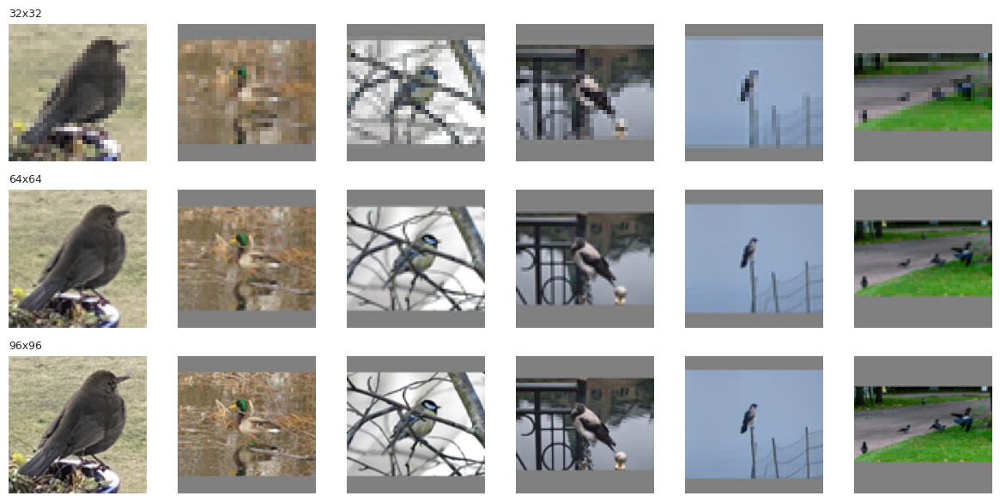

In [ ]:
fig, axs = plt.subplots(3, 6, figsize=(12, 6))
rows = train_df.sample(6, random_state=RANDOM_SEED)
for c, f in enumerate(rows["file"]):
    for r, size in enumerate([32, 64, 96]):
        axs[r, c].imshow(load_img(f, size)); axs[r, c].axis("off")
        if c == 0:
            axs[r, c].set_title("%dx%d" % (size, size), fontsize=9, loc="left")
plt.tight_layout()

# 4. Preliminary Model Development

## 4.1 Effect of Image Resolution

To assess the effect of image resolution, we trained the same baseline convolutional neural network (CNN) using images resized to 32$\times$32, 64$\times$64 and 96$\times$96 pixels. The network consists of three convolutional blocks with 32, 64 and 128 filters, respectively. Each block uses a 3$\times$3 convolution with same padding, a Leaky ReLU activation, 2$\times$2 max pooling and dropout. The resulting feature maps are flattened and passed to a 128-unit dense layer with Leaky ReLU activation and dropout, followed by a four-unit softmax output layer for species classification. The model is trained using the Adam optimizer and sparse categorical cross-entropy loss.

All other model settings were kept constant across resolutions, including the use of dropout, the absence of data augmentation, a batch size of 50 and a learning rate of \(10$^{-3}$\). We evaluated each resolution using the same five held-out folds, with two random seeds per fold, giving ten runs per resolution. In each run, one fold was held out for evaluation, the next fold was used for early stopping, and the remaining three folds were used for training. Performance was measured using macro-F1 to account for differences in species representation.

Higher resolutions increase computational cost because the number of input pixels grows with image dimensions. They may also increase the amount of information the network must learn to use effectively. We therefore selected the smallest resolution whose mean macro-F1 was reasonably close to the best-performing resolution, taking the observed run-to-run variability into account.

In [ ]:
def build_cnn(n_classes=4, size=32, filters=(32,64,128), dropout=True, gap=False, aug="none", lr=1e-3):
    m = keras.Sequential()
    m.add(layers.Input(shape=(size, size, 3)))

    # Data augmentation
    if aug in ("base", "strong"): # random flip and shift
        m.add(layers.RandomFlip("horizontal"))
        m.add(layers.RandomTranslation(0.1, 0.1))

    if aug == "strong": # zoom, rotation, brightness, contrast
        m.add(layers.RandomZoom(0.2))
        m.add(layers.RandomRotation(0.05))
        m.add(layers.RandomBrightness(0.2, value_range=(0, 1)))
        m.add(layers.RandomContrast(0.2))

    # Convolutional blocks
    filter_sizes = filters
    for k, filters in enumerate(filter_sizes):
        m.add(layers.Conv2D(filters, (3, 3), padding="same"))
        m.add(layers.LeakyReLU(negative_slope=0.1))
        m.add(layers.MaxPooling2D((2, 2)))

        if dropout:
            m.add(layers.Dropout(0.25 if k < len(filter_sizes)-1 else 0.5))

    # Classification head
    m.add(layers.GlobalAveragePooling2D() if gap else layers.Flatten())

    m.add(layers.Dense(128))
    m.add(layers.LeakyReLU(negative_slope=0.1))

    if dropout:
        m.add(layers.Dropout(0.3))

    m.add(layers.Dense(n_classes, activation="softmax"))      # one probability per species
    m.compile(loss="sparse_categorical_crossentropy", optimizer=keras.optimizers.Adam(learning_rate=lr), metrics=["accuracy"])
    return m

def eval_model(
    X,
    y,
    fold_ids,
    n_classes=4,
    size=None,
    filters=(32, 64, 128),
    dropout=True,
    gap=False,
    aug="none",
    lr=1e-3,
    epochs=50,
    patience=8,
    batch_size=50,
    test_folds=(0, 1, 2, 3, 4),
    seeds=(0, 1)
):
    if size is None:
        size = X.shape[1]

    scores = []

    for k in test_folds:
        te = np.where(fold_ids == k)[0]
        va = np.where(fold_ids == (k + 1) % 5)[0]
        tr = np.where(~np.isin(fold_ids, [k, (k + 1) % 5]))[0]

        for seed in seeds:
            keras.backend.clear_session()
            keras.utils.set_random_seed(seed)

            model = build_cnn(
                n_classes=n_classes,
                size=size,
                filters=filters,
                dropout=dropout,
                gap=gap,
                aug=aug,
                lr=lr
            )

            early_stop = keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=patience,
                restore_best_weights=True
            )

            model.fit(
                X[tr], y[tr],
                batch_size=batch_size,
                epochs=epochs,
                validation_data=(X[va], y[va]),
                callbacks=[early_stop],
                verbose=0
            )

            pred = model.predict(X[te], verbose=0).argmax(axis=1)

            scores.append(
                f1_score(y[te], pred, average="macro")
            )

    return np.mean(scores), np.std(scores)

K = 4

y = train_df["species"].map(
    {s: i for i, s in enumerate(SPECIES[:K])}
).to_numpy()

fold_ids = train_df["fold"].to_numpy()

# Load each resolution only once
X_by_size = {
    size: np.array([
        load_img(f, size) for f in train_df["file"]
    ])
    for size in (32, 64, 96)
}


# Resolution comparison: default baseline CNN
res = {}

for size in (32, 64, 96):
    mean_f1, std_f1 = eval_model(
        X=X_by_size[size],
        y=y,
        fold_ids=fold_ids,
        n_classes=K,
        size=size,
        filters=(32, 64, 128),
        dropout=True,
        gap=False,
        aug="none",
        epochs=50,
        patience=8,
        batch_size=50,
        test_folds=(0, 1, 2, 3, 4),
        seeds=(0, 1)
    )

    res[size] = (mean_f1, std_f1)

    print(
        f"{size:3d}x{size:<3d} macro-F1 "
        f"{mean_f1:.3f} +- {std_f1:.3f}"
    )

pd.DataFrame.from_dict(res, orient="index", columns=["mean_F1", "std"]).rename_axis("resolution").to_csv("/content/resolution_k4.csv")

 32x32  macro-F1 0.493 +- 0.030
 64x64  macro-F1 0.459 +- 0.050
 96x96  macro-F1 0.388 +- 0.063


With the baseline CNN, consisting of three convolutional blocks, dropout and no data augmentation, macro-F1 decreases as image resolution increases: from 0.493 at 32$\times$32 to 0.459 at 64$\times$64 and 0.388 at 96$\times$96. The higher resolutions therefore provide no improvement for this architecture, with the 96$\times$96 model performing notably worse. A possible reason is that the first dense layer grows with the image area (about 0.26 M, 1.05 M and 2.4 M parameters at the three sizes), which invites memorisation with about 1,500 training photos. We therefore use 32$\times$32 for the initial model comparisons. Because the best size may depend on the network, we test the size again later.

## 4.2 CNN Architecture and Regularisation Choices

Starting from the baseline CNN with 32$\times$32 pixel images and three convolutional blocks, we investigate several architectural and regularization choices. These include removing dropout, adding data augmentation through random horizontal flips and translations of up to 10%, replacing the Flatten layer with global average pooling (GAP), and increasing the network depth to four convolutional blocks. We also test the combination of GAP and data augmentation, as well as combining the fourth convolutional block with augmentation. Each configuration is evaluated across all five held-out folds, using two random seeds per fold, resulting in ten runs per configuration. In each run, one fold is held out for evaluation, the next fold is used for early stopping, and the remaining three folds are used for training. Performance is compared using macro-F1.

In [ ]:
X = X_by_size[32]

configs = {"baseline":            {"filters": (32, 64, 128)},
           "no dropout":          {"filters": (32, 64, 128), "dropout": False},
           "augmentation":        {"filters": (32, 64, 128), "aug": "base"},
           "gap":                 {"filters": (32, 64, 128), "gap": True},
           "gap + augmentation":  {"filters": (32, 64, 128), "gap": True, "aug": "base"},
           "4 conv blocks":       {"filters": (32, 64, 128, 128)},
           "4 conv blocks + augmentation":  {"filters": (32, 64, 128, 128), "aug": "base"},
}

print("32x32 RESOLUTION\n")

rows = []
for name, cfg in configs.items():
    m, s = eval_model(
        X=X,
        y=y,
        fold_ids=fold_ids,
        n_classes=K,
        size=32,
        epochs=50,
        patience=8,
        batch_size=50,
        test_folds=(0, 1, 2, 3, 4),
        seeds=(0, 1),
        **cfg
    )

    rows.append((name, m, s))
    print(f"{name:30s} macro-F1 {m:.3f} +- {s:.3f}")

results = pd.DataFrame(rows, columns=["setting", "mean_F1", "std_4_runs"])
results.to_csv("/content/ladder_models.csv", index=False)

32x32 RESOLUTION

baseline                       macro-F1 0.493 +- 0.030
no dropout                     macro-F1 0.437 +- 0.058
augmentation                   macro-F1 0.537 +- 0.057
gap                            macro-F1 0.433 +- 0.067
gap + augmentation             macro-F1 0.351 +- 0.104
4 conv blocks                  macro-F1 0.519 +- 0.037
4 conv blocks + augmentation   macro-F1 0.544 +- 0.048


The baseline CNN achieves a macro-F1 of 0.493 $\pm$ 0.030 across the four species. Removing dropout reduces macro-F1 to 0.437 $\pm$ 0.058, suggesting that dropout is beneficial for generalization on this relatively small dataset. Data augmentation improves performance to 0.537 $\pm$ 0.057, while adding a fourth convolutional block raises the score to 0.519 $\pm$ 0.037. Replacing Flatten with global average pooling (GAP) reduces macro-F1 to 0.433 $\pm$ 0.067, and combining GAP with augmentation performs even worse, reaching 0.351 $\pm$ 0.104. This suggests that GAP is not beneficial in the tested architecture. The combination of augmentation and four convolutional blocks achieves the highest mean macro-F1 of 0.544 $\pm$ 0.048, but the improvement over augmentation alone is small relative to the observed variability. Overall, data augmentation appears to be the most useful individual modification, while GAP and removing dropout reduce performance.

Having established the initial design choices at 32$\times$32 pixels, we next investigate whether increasing the image resolution to 64$\times$64 improves performance for different CNN architectures. We compare three configurations: the three-block baseline CNN with data augmentation, the deeper four-block CNN without augmentation, and the four-block CNN with data augmentation. This allows us to examine how model depth and augmentation affect performance at the higher resolution. Each configuration is evaluated again across all five held-out folds, using two random seeds per fold. In each run, one fold is held out for evaluation, the next fold is used for early stopping, and the remaining three folds are used for training. Performance is compared using macro-F1.

In [ ]:
res_rows = []

experiments = [
    ("augmentation", 64, dict(filters=(32, 64, 128), aug="base")),
    ("4 conv blocks", 64, dict(filters=(32, 64, 128, 128), aug="none")),
    ("augmentation + 4 conv blocks", 64, dict(filters=(32, 64, 128, 128), aug="base")),
]

print("64x64 RESOLUTION")
print()

for name, size, cfg in experiments:
    m, s = eval_model(
        X=X_by_size[size],
        y=y,
        fold_ids=fold_ids,
        n_classes=K,
        size=size,
        dropout=True,
        epochs=50,
        patience=8,
        batch_size=50,
        test_folds=(0, 1, 2, 3, 4),
        seeds=(0, 1),
        **cfg
    )

    res_rows.append((name, m, s))
    print(f"{name:48s} macro-F1 {m:.3f} +- {s:.3f}")

results_df = pd.DataFrame(res_rows, columns=["setting", "mean_F1", "std_4_runs"])
results_df.to_csv("/content/ladder_resolution64.csv", index=False)

64x64 RESOLUTION

augmentation                                     macro-F1 0.504 +- 0.084
4 conv blocks                                    macro-F1 0.531 +- 0.029
augmentation + 4 conv blocks                     macro-F1 0.501 +- 0.155


At 64$\times$64, the four-block model without augmentation achieved a macro-F1 of 0.531 $\pm$ 0.029, compared with 0.519 $\pm$ 0.037 at 32$\times$32 resolution. In contrast, the three-block CNN with augmentation scored 0.504 $\pm$ 0.084 at 64$\times$64, compared with 0.537 $\pm$ 0.057 at 32$\times$32. Combining four convolutional blocks with augmentation also reduced performance, achieving 0.501 $\pm$ 0.155 at 64$\times$64 compared with 0.544 $\pm$ 0.048 at 32$\times$32.

These results suggest that the effect of increasing image resolution depends on the model architecture and training configuration. The four-block architecture without augmentation showed a modest improvement at the higher resolution, whereas both augmented configurations performed worse at 64$\times$64 than at 32$\times$32. The relatively large standard deviations for the augmented models at 64$\times$64, particularly the four-block model, also indicate substantial variability across folds and random seeds. Therefore, increasing resolution alone does not consistently improve performance, and the benefit may depend on the interaction between architecture and augmentation.

To investigate whether stronger augmentation improves performance, we introduce random zoom, rotation, brightness, and contrast transformations in addition to horizontal flips and translations. We evaluate this stronger augmentation strategy at both 32$\times$32 and 64$\times$64 resolutions, using both the three-block and four-block CNN architectures. This allows us to compare the effect of stronger augmentation across image resolutions and model depths.

In [ ]:
experiments = [
    ("32x32, 3 blocks, strong augmentation", 32, (32, 64, 128)),
    ("64x64, 3 blocks, strong augmentation", 64, (32, 64, 128)),
    ("32x32, 4 blocks, strong augmentation", 32, (32, 64, 128, 128)),
    ("64x64, 4 blocks, strong augmentation", 64, (32, 64, 128, 128)),
]

rows = []
for name, size, filters in experiments:
    m, s = eval_model(
        X=X_by_size[size],
        y=y,
        fold_ids=fold_ids,
        n_classes=K,
        size=size,
        filters=filters,
        dropout=True,
        gap=False,
        aug="strong",
        epochs=50,
        patience=8,
        batch_size=50,
        test_folds=(0, 1, 2, 3, 4),
        seeds=(0, 1)
    )

    rows.append((name, m, s))
    print(f"{name:45s} macro-F1 {m:.3f} +- {s:.3f}")

results = pd.DataFrame(rows, columns=["setting", "mean_F1", "std"])
results.to_csv("/content/strong_augmentation_comparison.csv", index=False)

32x32, 3 blocks, strong augmentation          macro-F1 0.491 +- 0.059
64x64, 3 blocks, strong augmentation          macro-F1 0.492 +- 0.075
32x32, 4 blocks, strong augmentation          macro-F1 0.493 +- 0.047
64x64, 4 blocks, strong augmentation          macro-F1 0.545 +- 0.070


The results show that the four-block CNN with stronger augmentation at 64$\times$64 achieved the highest macro-F1 of 0.545 $\pm$ 0.070. For the three-block architecture, increasing the resolution from 32$\times$32 to 64$\times$64 resulted in virtually no change in performance, with macro-F1 increasing from 0.491 $\pm$ 0.059 to 0.492 $\pm$ 0.075. In contrast, the four-block model improved from 0.493 $\pm$ 0.047 at 32$\times$32 to 0.545 $\pm$ 0.070 at 64$\times$64. This suggests that the effect of increasing resolution depends on model depth, with the deeper architecture benefiting more from the higher resolution when combined with stronger augmentation. However, the standard deviation for the 64$\times$64 four-block model indicates some variability across folds and random seeds. Furthermore, its performance was only slightly higher than that of the four-block model at 64$\times$64 without augmentation, which achieved 0.531 $\pm$ 0.029. Therefore, stronger augmentation may benefit the deeper model at higher resolution, but the improvement is modest relative to the observed variability.

## 4.3 Selected Baseline CNN

Since model selection was conducted using cross-validation on the development dataset, we select the four-block CNN with 32$\times$32 input images, a Flatten layer, dropout, and base data augmentation as our final architecture. It achieved a mean macro-F1 of 0.544 $\pm$ 0.048, comparable to the 0.545 $\pm$ 0.070 obtained by the four-block model with strong augmentation at 64$\times$64 resolution. We favor the lower resolution because it requires less computation while achieving a similar mean performance. We use the cross-validation results to determine the training procedure and epoch count before retraining the selected model on the full development dataset.

Fold 0: macro-F1 = 0.463, best epoch = 31
Fold 1: macro-F1 = 0.480, best epoch = 20
Fold 2: macro-F1 = 0.556, best epoch = 35
Fold 3: macro-F1 = 0.478, best epoch = 36
Fold 4: macro-F1 = 0.581, best epoch = 32

Mean fold macro-F1: 0.511 +/- 0.053
Best epochs: [np.int64(31), np.int64(20), np.int64(35), np.int64(36), np.int64(32)]
Median best epoch: 32
Pooled out-of-fold macro-F1: 0.509 | accuracy: 0.526


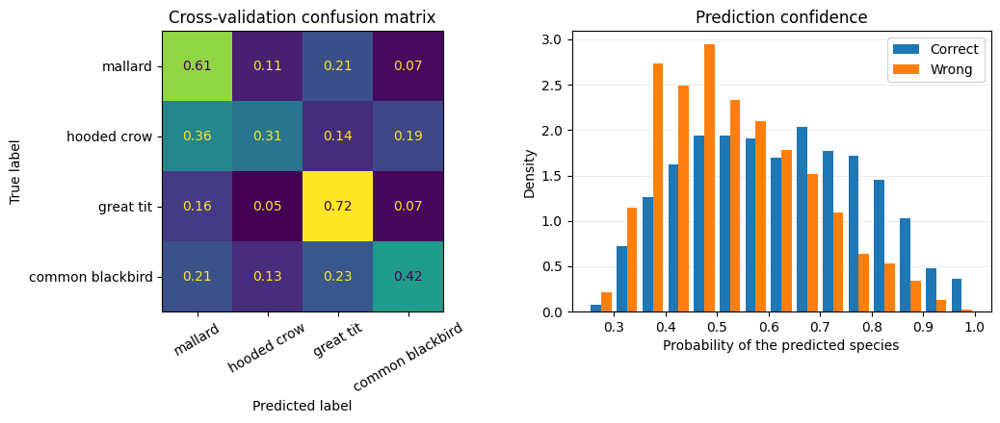

Wrong predictions: 754 | share with probability above 0.8: 0.05


In [ ]:
# Selected model: 32x32, 4 blocks, base augmentation
SIZE = 32
FILTERS = (32, 64, 128, 128)
AUG = "base"

X = X_by_size[SIZE]

# Out-of-fold class probabilities
proba = np.zeros((len(train_df), K))
fold_scores = []
best_epochs = []

for k in range(5):
    te = np.where(fold_ids == k)[0]
    va = np.where(fold_ids == (k + 1) % 5)[0]
    tr = np.where(~np.isin(fold_ids, [k, (k + 1) % 5]))[0]

    keras.backend.clear_session()
    keras.utils.set_random_seed(RANDOM_SEED)

    model = build_cnn(
        n_classes=K,
        size=SIZE,
        filters=FILTERS,
        dropout=True,
        gap=False,
        aug=AUG
    )

    es = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
    )

    history = model.fit(
        X[tr], y[tr],
        batch_size=50,
        epochs=50,
        validation_data=(X[va], y[va]),
        callbacks=[es],
        verbose=0
    )

    best_epoch = np.argmin(history.history["val_loss"]) + 1
    best_epochs.append(best_epoch)

    # Evaluate on the held-out evaluation fold
    proba[te] = model.predict(X[te], verbose=0)
    fold_f1 = f1_score(
        y[te], proba[te].argmax(axis=1),
        average="macro"
    )
    fold_scores.append(fold_f1)

    print(
        f"Fold {k}: macro-F1 = {fold_f1:.3f}, "
        f"best epoch = {best_epoch}"
    )

print(f"\nMean fold macro-F1: {np.mean(fold_scores):.3f} "
      f"+/- {np.std(fold_scores, ddof=1):.3f}")
print(f"Best epochs: {best_epochs}")
print(f"Median best epoch: {int(np.median(best_epochs))}")

# Pooled out-of-fold performance
true = y
pred = proba.argmax(axis=1)
conf = proba.max(axis=1)

print(
    "Pooled out-of-fold macro-F1: %.3f | accuracy: %.3f"
    % (
        f1_score(true, pred, average="macro"),
        accuracy_score(true, pred)
    )
)

# Normalised confusion matrix and confidence distributions
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay.from_predictions(
    true,
    pred,
    labels=np.arange(K),
    display_labels=short,
    normalize="true",
    ax=axs[0],
    colorbar=False,
    xticks_rotation=30,
    values_format=".2f"
)
axs[0].set_title("Cross-validation confusion matrix")
axs[0].grid(False, which="both")

correct = true == pred
incorrect = ~correct

axs[1].hist(
    [conf[correct], conf[incorrect]],
    bins=15,
    range=(1 / K, 1.0),
    density=True,
    label=["Correct", "Wrong"]
)
axs[1].set_xlabel("Probability of the predicted species")
axs[1].set_ylabel("Density")
axs[1].set_title("Prediction confidence")
axs[1].legend()
axs[1].set_axisbelow(True)
axs[1].grid(axis="y", alpha=0.25)
axs[1].grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

# Confident mistakes
wrong = np.where(incorrect)[0]

high_conf_share = np.mean(conf[wrong] > 0.8) if len(wrong) else 0.0

print(
    "Wrong predictions: %d | share with probability above 0.8: %.2f"
    % (len(wrong), high_conf_share)
)

The selected CNN achieved a mean fold macro-F1 score of 0.511 $\pm$ 0.053. The pooled out-of-fold macro-F1 score was 0.509, with an accuracy of 0.526. These results indicate that the model can distinguish some of the bird species, but its overall classification performance remains moderate. The variation in fold scores, which ranged from 0.463 to 0.581, also suggests that performance depends on the particular groups of photographers represented in each evaluation fold.

The normalized confusion matrix reveals substantial differences in performance between species. Great tits were classified most successfully, with 72% of their images correctly identified. Mallards had a lower correct classification rate of 61%, while common blackbirds and hooded crows were more difficult to classify, with correct classification rates of 42% and 31%, respectively. Hooded crows were frequently misclassified as mallards (36%), while common blackbirds were often predicted to be great tits (23%). Mallards were also commonly confused with great tits (21%).

The prediction-confidence histogram shows that correct and incorrect predictions have overlapping confidence distributions, with many predictions in both groups having probabilities between approximately 0.35 and 0.70. Incorrect predictions are therefore not always associated with very low confidence. However, only around 5% of incorrect predictions had a maximum predicted probability above 0.8, indicating that highly confident errors were relatively uncommon.

Overall, the out-of-fold analysis suggests that the selected architecture provides a useful baseline but does not classify all four species equally well. The confusion matrix identifies the most challenging species and pairs of classes, while the confidence analysis helps characterize the model's errors.

Next, we retrain the selected CNN on the entire development training set to make use of all available training images. The final model retains the four-block architecture, dropout, and basic data augmentation, with the number of training epochs set to 32, corresponding to the median best epoch across the five evaluation runs. The trained model is then used to make predictions on the independent test set.

In [ ]:
final_epochs = 32

keras.backend.clear_session()
keras.utils.set_random_seed(RANDOM_SEED)

final_model = build_cnn(
    n_classes=K,
    size=SIZE,
    filters=FILTERS,
    dropout=True,
    gap=False,
    aug=AUG
)

final_model.fit(
    X_by_size[SIZE],
    y,
    batch_size=50,
    epochs=final_epochs,
    verbose=1
)

Epoch 1/32
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.2684 - loss: 1.3935
Epoch 2/32
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.2898 - loss: 1.3834
Epoch 3/32
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.3180 - loss: 1.3664
Epoch 4/32
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.3400 - loss: 1.3501
Epoch 5/32
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.3734 - loss: 1.3245
Epoch 6/32
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.3916 - loss: 1.3069
Epoch 7/32
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.3979 - loss: 1.2946
Epoch 8/32
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.4507 - loss: 1.2474
Epoch 9/32
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.4676 - loss: 1.2155
Epoch 10/32
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.4758 - loss: 1.2086
Epoch 11/32
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.5003 - loss: 1.1725
Epoch 12/32
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - accuracy:

Once training is complete, we evaluate the final model on the independent test set, which was held out before model development and contains images from photographers not represented in the development set. We calculate macro-F1 and accuracy to assess overall predictive performance. We also examine a normalized confusion matrix to identify species that are frequently confused, and compare prediction confidence for correct and incorrect classifications. Finally, we inspect selected misclassified images to explore potential sources of error, such as visual similarity between species or image quality.

Test macro-F1: 0.574
Test accuracy: 0.585


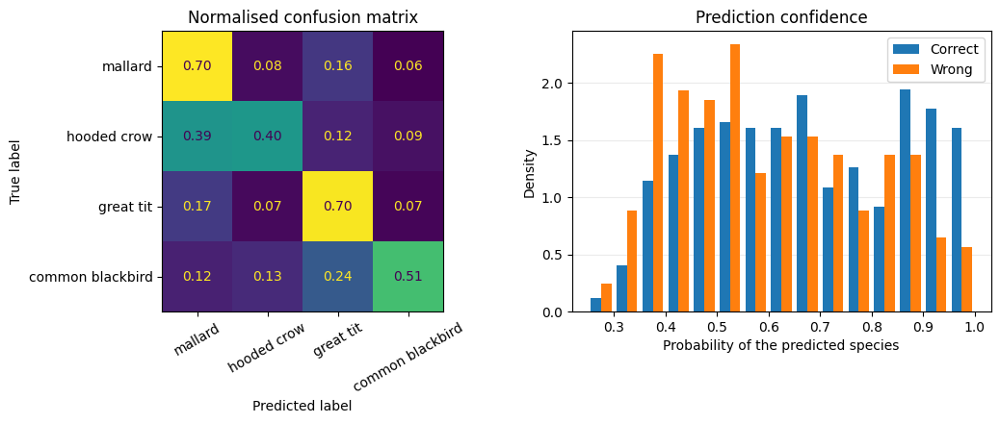

Wrong predictions: 248 | share with probability above 0.8: 0.20


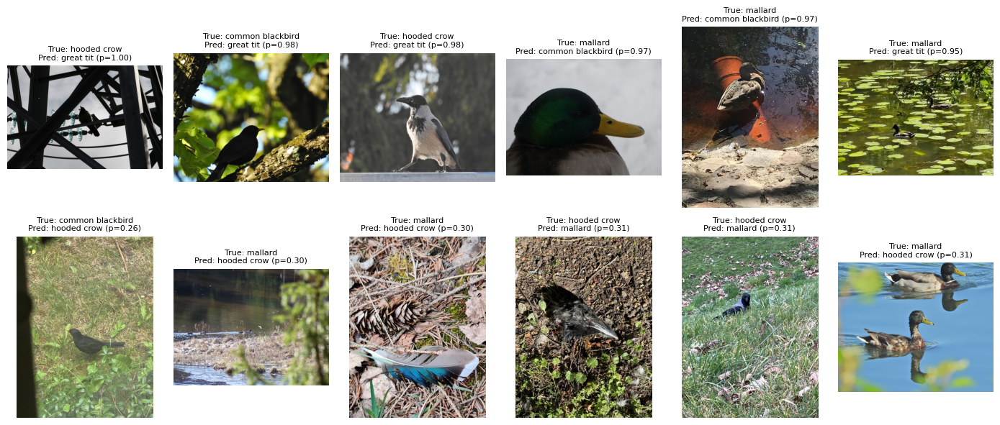

In [ ]:
Xtest = np.array([
    load_img(f, 32) for f in test_df["file"]
])

ytest = test_df["species"].map(
    {sp: i for i, sp in enumerate(SPECIES[:K])}
).to_numpy()

true = ytest
proba_test = final_model.predict(Xtest, verbose=0)
pred = proba_test.argmax(axis=1)
conf = proba_test.max(axis=1)

print(f"Test macro-F1: {f1_score(true, pred, average='macro'):.3f}")
print(f"Test accuracy: {accuracy_score(true, pred):.3f}")

# Normalised confusion matrix and confidence of correct vs wrong predictions
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay.from_predictions(
    true,
    pred,
    labels=np.arange(K),
    display_labels=short,
    normalize="true",
    ax=axs[0],
    colorbar=False,
    xticks_rotation=30,
    values_format=".2f"
)

axs[0].set_title("Normalised confusion matrix")
axs[0].grid(False, which="both")

correct = true == pred
incorrect = ~correct

axs[1].hist(
    [conf[correct], conf[incorrect]],
    bins=15,
    range=(1 / K, 1.0),
    density=True,
    label=["Correct", "Wrong"]
)
axs[1].set_xlabel("Probability of the predicted species")
axs[1].set_ylabel("Density")
axs[1].legend()
axs[1].set_title("Prediction confidence")
axs[1].set_axisbelow(True)
axs[1].grid(axis="y", alpha=0.25)
axs[1].grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

# Confident mistakes
wrong = np.where(incorrect)[0]

high_conf_share = np.mean(conf[wrong] > 0.8) if len(wrong) else 0.0

print(
    "Wrong predictions: %d | share with probability above 0.8: %.2f"
    % (len(wrong), high_conf_share)
)

# Six most confident mistakes and six most uncertain mistakes
if len(wrong):
    order = wrong[np.argsort(-conf[wrong])]
    most_confident = order[:6]
    most_uncertain = order[-6:][::-1]
    show = list(most_confident) + list(most_uncertain)

    fig, axs = plt.subplots(2, 6, figsize=(14, 6))

    for a, j in zip(axs.ravel(), show):
        img = Image.open(IMG_DIR / test_df["file"].iloc[j])
        a.imshow(img)
        a.axis("off")
        a.set_title(
            "True: %s\nPred: %s (p=%.2f)"
            % (short[true[j]], short[pred[j]], conf[j]),
            fontsize=8
        )

    # Hide unused axes if fewer than 12 mistakes
    for a in axs.ravel()[len(show):]:
        a.axis("off")

    plt.tight_layout()
    plt.show()

The final model achieved a macro-F1 score of 0.574 and an accuracy of 0.585 on the independent test set. The normalized confusion matrix shows that performance varies substantially between species. Great tits and mallards were classified most successfully, both having 70% of their images correctly identified. 51% of common blackbirds were correctly classified. Hooded crows were the most challenging class, with 40% correctly identified. The model frequently confused hooded crows with mallards (39%) and common blackbirds with great tits (24%).

The prediction-confidence distribution shows considerable overlap between correct and incorrect predictions. Many predictions in both groups have confidence values between approximately 0.4 and 0.7, indicating that the model is often uncertain about its classification. Nevertheless, some incorrect predictions receive high confidence scores: 20% of the incorrect predictions had a maximum predicted probability above 0.8. This suggests that the model sometimes assigns strong confidence to an incorrect species label.

Inspection of the misclassified images provides some additional context for these errors. Several hooded crows were classified as great tits, including images in which the bird occupies only a small part of the image, is partially obscured, or appears against a complex background. Other examples contain birds photographed from a distance or under challenging lighting conditions. Such characteristics may make species-specific features difficult to distinguish, particularly after images are resized to 32$\times$32 pixels. The high-confidence mistakes also demonstrate that the model can make incorrect predictions even when its output strongly favors one class. However, these examples are illustrative and do not establish the causes of all classification errors.

Overall, the final model generalizes to the independent test set with moderate performance, but its predictions remain uneven across species. Great tits and mallards are recognized relatively reliably, whereas hooded crows remain difficult to classify. The confusion matrix and inspection of misclassified images suggest that low image resolution, background complexity, bird size within the image, and visual similarities between classes may contribute to the observed errors. These findings highlight the limitations of the selected CNN and provide directions for future improvements, such as preserving more image detail or investigating methods that focus more directly on the bird itself.

# 5. Transfer Learning with ResNet50

Our custom CNN was trained from scratch on a relatively small dataset. To investigate whether features learned from a much larger dataset could improve classification performance, we implemented a transfer-learning approach using ResNet50 pre-trained on ImageNet.

Rather than fine-tuning the network, we kept all ResNet50 layers frozen (`resnet.trainable = False`) and used the model as a fixed feature extractor. Each image was resized to 224$\times$224 pixels and processed using the preprocessing function corresponding to the ImageNet weights. The original 1000-class classification head was removed (`include_top=False`), and global average pooling (`pooling="avg"`) was applied to produce a 2,048-dimensional feature vector for each image.

We then trained a logistic regression classifier on these features, using standardisation and an L2-regularised logistic regression model with \(C=0.1\). Performance was evaluated using the same grouped fold assignments and training/evaluation scheme as the custom CNN, allowing a more direct comparison between the approaches.

In [ ]:
# Feature extractor: ResNet50 with ImageNet weights, without its 1000-class classifier (include_top=False)
# pooling="avg" averages the last feature maps into one vector of 2048 numbers per photo
resnet = ResNet50(weights="imagenet", include_top=False, pooling="avg", input_shape=(224, 224, 3))
resnet.trainable = False                                  # frozen: we only read features

def extract_resnet(files, batch=64):
    feats = []
    for i in range(0, len(files), batch):                 # in batches, so the 224x224 photos fit in memory
        xb = np.stack([load_img(f, 224) for f in files[i:i + batch]]) * 255.0    # load_img gives [0, 1], ResNet50 expects 0-255
        feats.append(resnet.predict(preprocess_input(xb), verbose=0))            # preprocess_input: the normalisation ResNet50 was trained with
        if (i // batch) % 10 == 0:
            print(i, "of", len(files))
    return np.concatenate(feats)

F_res = extract_resnet(train_df["file"].tolist())         # (number of photos, 2048)

os.makedirs("results", exist_ok=True)
np.save("results/features_resnet50_224.npy", F_res)       # saved, so the features are never recomputed
print(F_res.shape)

def eval_logreg(F, K=4, test_folds=(0, 1, 2, 3, 4)):
    # Same folds as everywhere else; the validation fold is left out of training so the training sets are the same size
    out = []
    for k in test_folds:
        te = np.where(fold_ids == k)[0]
        val_fold = (k + 1) % 5
        tr = np.where(~np.isin(fold_ids, [k, val_fold]))[0]
        clf = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000)).fit(F[tr], y[tr])
        out.append(f1_score(y[te], clf.predict(F[te]), average="macro"))
    return np.mean(out), np.std(out, ddof=1)

m, s = eval_logreg(F_res)
print("ResNet50 (ImageNet), frozen + logistic regression   macro-F1 %.3f +- %.3f" % (m, s))

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
0 of 1591
640 of 1591
1280 of 1591
(1591, 2048)
ResNet50 (ImageNet), frozen + logistic regression   macro-F1 0.868 +- 0.015


The frozen ResNet50 feature extractor produced a 2,048-dimensional feature vector for each of the 1,591 development images. Using grouped cross-validation, the logistic regression classifier achieved a mean macro-F1 score of 0.868 across the five evaluation folds, with a standard deviation of 0.015. The relatively small variation between folds indicates consistent performance across the evaluated groups of photographers.

These results suggest that the visual representations learned by ResNet50 from ImageNet transfer effectively to bird species classification. By using pre-trained features instead of learning all visual representations from scratch, this approach achieved substantially stronger cross-validation performance than the custom CNN. The final classifier was subsequently fitted on the full development set and evaluated on the independent test set.

0 of 597
ResNet50 test macro-F1: 0.832
ResNet50 test accuracy: 0.843


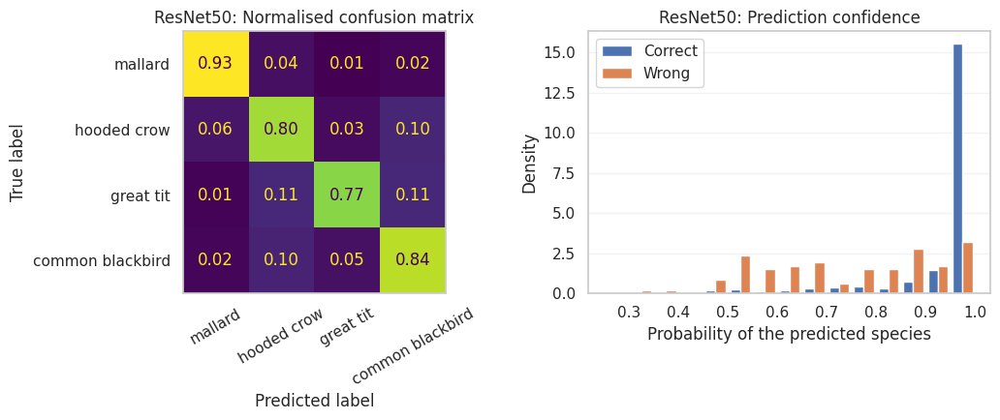

ResNet50 wrong predictions: 94 | share with probability above 0.8: 0.46


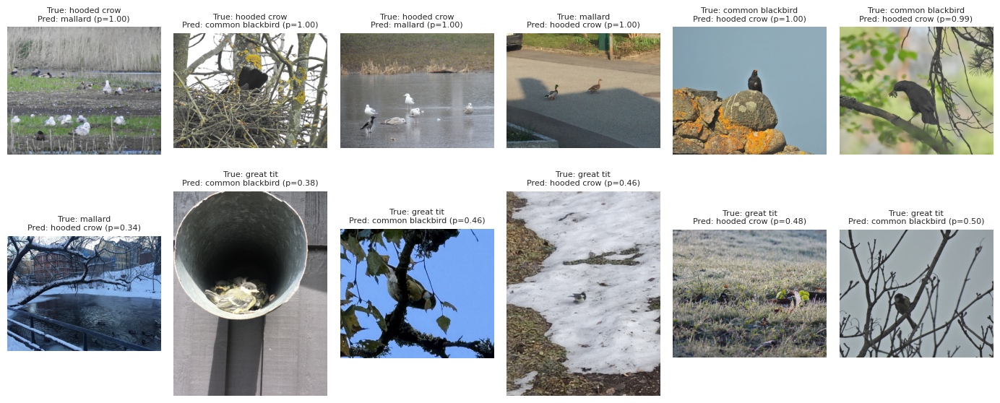

In [ ]:
# Fit the final classifier on ALL development images
final_logreg = make_pipeline(
    StandardScaler(),
    LogisticRegression(C=0.1, max_iter=2000)
)
final_logreg.fit(F_res, y)

# Extract features from the independent test images
F_test_res = extract_resnet(test_df["file"].tolist())

# True test labels
ytest = test_df["species"].map(
    {sp: i for i, sp in enumerate(SPECIES[:K])}
).to_numpy()

# Predict test labels
pred_test_res = final_logreg.predict(F_test_res)

# Evaluate once on the test set
print("ResNet50 test macro-F1:",
      round(f1_score(ytest, pred_test_res, average="macro"), 3))
print("ResNet50 test accuracy:",
      round(accuracy_score(ytest, pred_test_res), 3))

# Normalised confusion matrix and confidence of correct vs wrong predictions

true = ytest
pred = pred_test_res

# Predicted-class probabilities from the final ResNet50 + logistic regression model
proba_res_test = final_logreg.predict_proba(F_test_res)
conf = proba_res_test.max(axis=1)

fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))

ConfusionMatrixDisplay.from_predictions(
    true,
    pred,
    labels=np.arange(K),
    display_labels=short,
    normalize="true",
    ax=axs[0],
    colorbar=False,
    xticks_rotation=30,
    values_format=".2f"
)

axs[0].set_title("ResNet50: Normalised confusion matrix")
axs[0].grid(False, which="both")

correct = true == pred
incorrect = ~correct

axs[1].hist(
    [conf[correct], conf[incorrect]],
    bins=15,
    range=(1 / K, 1.0),
    density=True,
    label=["Correct", "Wrong"]
)
axs[1].set_xlabel("Probability of the predicted species")
axs[1].set_ylabel("Density")
axs[1].legend()
axs[1].set_title("ResNet50: Prediction confidence")
axs[1].set_axisbelow(True)
axs[1].grid(axis="y", alpha=0.25)
axs[1].grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

# Confident mistakes
wrong = np.where(incorrect)[0]

high_conf_share = np.mean(conf[wrong] > 0.8) if len(wrong) else 0.0

print(
    "ResNet50 wrong predictions: %d | share with probability above 0.8: %.2f"
    % (len(wrong), high_conf_share)
)

# Six most confident mistakes and six most uncertain mistakes
if len(wrong):
    order = wrong[np.argsort(-conf[wrong])]
    most_confident = order[:6]
    most_uncertain = order[-6:][::-1]
    show = list(most_confident) + list(most_uncertain)

    fig, axs = plt.subplots(2, 6, figsize=(14, 6))

    for a, j in zip(axs.ravel(), show):
        img = Image.open(IMG_DIR / test_df["file"].iloc[j])
        a.imshow(img)
        a.axis("off")
        a.set_title(
            "True: %s\nPred: %s (p=%.2f)"
            % (short[true[j]], short[pred[j]], conf[j]),
            fontsize=8
        )

    # Hide unused axes if fewer than 12 mistakes
    for a in axs.ravel()[len(show):]:
        a.axis("off")

    plt.tight_layout()
    plt.show()

The frozen ImageNet-pretrained ResNet50 combined with logistic regression achieved a macro-F1 score of 0.832 and an accuracy of 0.843 on the independent test set of 597 images, correctly classifying 503 images. This represents substantially stronger performance than the custom CNN. However, the two approaches are not directly comparable, as ResNet50 benefits from transfer learning using features learned from ImageNet, whereas the custom CNN is trained from scratch on the target dataset. Therefore, the results demonstrate the advantage of the transfer-learning approach in this setting, rather than isolating the effect of the model architecture alone.

The normalised confusion matrix shows that the ResNet50-based classifier distinguished the four bird species with varying degrees of success. Mallards were classified most consistently, with 93% of images correctly identified. Common blackbirds followed with 84%, while 80% of hooded crows were classified correctly. Great tits had the lowest correct classification rate, at 77%. These results indicate that, although the model classified most images correctly for every species, it had greater difficulty distinguishing great tits from the other species.

The prediction-confidence plot provides further insight into the model's performance. Correct predictions are concentrated at very high confidence levels, with many assigned probabilities close to 1.0. In contrast, incorrect predictions occur across a wider range of confidence levels, although some misclassifications are also made with high confidence. This suggests that the model is generally confident when classifying images correctly, but its predicted probabilities do not always reflect whether a prediction is correct.

The example misclassifications illustrate some of the challenges faced by the classifier. Several images contain multiple birds, distant subjects, or complex backgrounds, making the relevant species harder to distinguish. Other images show birds that occupy only a small part of the image or are partially obscured by branches or other objects. Notably, some of these difficult images receive very high predicted probabilities despite being classified incorrectly. These examples highlight that high prediction confidence does not necessarily guarantee a correct classification.

# 6. Controlled Image-Preprocessing Experiments

Four experiments examine how colour representation, training-time augmentation, deterministic image enhancement and input resolution affect a small convolutional neural network (CNN) trained on citizen-science bird photographs. The four classes are **Mallard, Hooded Crow, Great Tit and Common Blackbird**. Only the training subset is used for these comparisons; the independent held-out test subset is reserved for Section 7. Experiments 1–3 use **32 × 32** images, while Experiment 4 also considers **64 × 64** and **96 × 96**.

### Common experimental protocol

As before, photographs are converted to RGB, padded to a square with a neutral grey background to preserve aspect ratio, and resized using Lanczos resampling. Except where specified, the CNN contains four convolutional blocks with **32, 64, 128 and 128 filters**, LeakyReLU activations, max-pooling and dropout, followed by a 128-unit dense layer and four-class softmax output. Horizontal flipping and random translation are used for all models. Training uses Adam with a learning rate of **0.001**, batch size **50**, up to **50 epochs**, and early stopping on validation loss (**patience 8**, restoring the best weights).

The training subset is assigned to **five stratified grouped folds, grouped by photographer (`creator`)**, so photographs from the same photographer do not appear in different folds. For each rotation, one fold is used for assessment, the next fold (cyclically) for early stopping and the other three folds for fitting. Each configuration is repeated with **seeds 0 and 1**, resulting in ten fold–seed assessment scores per configuration. The held-out test data are not used to fit, validate or select configurations in Experiments 1–4.

The primary metric is **macro-F1**, giving equal weight to the four species. Balanced accuracy and species-level F1 provide complementary views. Reported means and standard deviations (SDs) summarize the ten fold–seed scores; these overlapping training runs **are not ten independent samples or confidence intervals**. For direct comparisons, score differences are paired by fold and seed, using the appropriate reference **within each experiment**. Species-level heatmaps show means across those same fold–seed assessments.


In [ ]:
# Shared plotting/analysis helpers for Experiments 1–4.
# All plots are produced from the actual fold-by-seed CV results (not test_df).


EXP_OUT = Path('experiment_outputs')
EXP_OUT.mkdir(parents=True, exist_ok=True)
EXP_COLORS = {
    "baseline": "#3A647D",
    "variant": "#D47A44",
    "points": "#8B96A0",
}
EXP_SHORT_NAMES = {
    "Anas platyrhynchos": "Mallard",
    "Corvus cornix": "Hooded crow",
    "Parus major": "Great tit",
    "Turdus merula": "Common blackbird",
}

def exp_plot_scores(results, category, order, title, save_as):
    """Show fold×seed scores plus descriptive mean±SD (not a CI)."""
    fig, ax = plt.subplots(figsize=(9.4, max(3.1, 0.7 * len(order) + 1)))
    rng = np.random.default_rng(123)  # reproducible plot jitter only
    for i, item in enumerate(order):
        values = results.loc[results[category] == item, 'macro_f1'].dropna().to_numpy()
        if not len(values):
            continue
        ax.scatter(values, i + rng.uniform(-0.12, 0.12, len(values)),
                   s=23, alpha=.6, color=EXP_COLORS['points'], zorder=2)
        mu = values.mean()
        sd = values.std(ddof=1) if len(values)>1 else 0.0
        ax.errorbar(mu, i, xerr=sd, fmt='o', color=EXP_COLORS['baseline'] if i==0
                    else EXP_COLORS['variant'], markersize=9, capsize=4,
                    linewidth=2, zorder=3)
        ax.text(min(.99, mu+.025), i-0.23, f'{mu:.3f}', fontsize=9)
    ax.set_yticks(range(len(order)), order)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel('Macro-F1 (points: fold × seed; dot and whiskers: mean ± SD)')
    ax.set_title(title, pad=14)
    ax.grid(axis='x', alpha=.2)
    ax.spines[['top','right','left']].set_visible(False)
    fig.tight_layout()
    fig.savefig(EXP_OUT/save_as, dpi=180, bbox_inches='tight')
    plt.show()

def exp_plot_deltas(deltas, title, save_as, order=None):
    """Paired fold×seed changes against a reference (positive = improvement)."""
    order = list(deltas.columns if order is None else order)
    vals = deltas.reindex(columns=order)
    allvals=vals.to_numpy(dtype=float)
    finite=allvals[np.isfinite(allvals)]
    bound=max(.03, 1.22*np.max(np.abs(finite))) if len(finite) else .03
    fig, ax=plt.subplots(figsize=(9.4, max(2.9, .7*len(order)+1)))
    rng=np.random.default_rng(123)
    for i, item in enumerate(order):
        arr=vals[item].dropna().to_numpy()
        if not len(arr): continue
        ax.scatter(arr, i+rng.uniform(-.13,.13,len(arr)), s=23, alpha=.55,
                   color=EXP_COLORS['points'], zorder=2)
        mu=arr.mean(); sd=arr.std(ddof=1) if len(arr)>1 else 0
        ax.errorbar(mu,i,xerr=sd,fmt='o',color=EXP_COLORS['variant'],
                    linewidth=2,capsize=4,markersize=9,zorder=3)
        ax.text(mu + (.03*bound if mu<=0 else -.03*bound), i-.23,
                f'{mu:+.3f}',fontsize=9,ha='left' if mu<=0 else 'right')
    ax.axvline(0, color='#394956', lw=1.3, ls='--')
    ax.set_yticks(range(len(order)),order)
    ax.invert_yaxis()
    ax.set_xlim(-bound,bound)
    ax.set_xlabel('Paired change in macro-F1 (fold × seed; mean ± SD)')
    ax.set_title(title,pad=14)
    ax.grid(axis='x',alpha=.2)
    ax.spines[['top','right','left']].set_visible(False)
    fig.tight_layout()
    fig.savefig(EXP_OUT/save_as,dpi=180,bbox_inches='tight')
    plt.show()

def exp_species_f1(predictions, y, condition_fields, labels=SPECIES[:4]):
    """Calculate per-species F1 per assessment fold and seed, not only seed 0.
    Returns individual run×species scores for descriptive comparisons.
    """
    result=[]
    for r in predictions:
        true=np.asarray(y)[r['indices']]
        pred=np.asarray(r['pred'])
        scores=f1_score(true, pred, labels=np.arange(len(labels)),
                        average=None, zero_division=0)
        for name, f1 in zip(labels, scores):
            result.append({**{field:r[field] for field in condition_fields},
                           'fold':r['fold'], 'seed':r['seed'],
                           'species':name, 'f1':float(f1)})
    return pd.DataFrame(result)

def exp_plot_species(species_table, title, save_as):
    """Consistent annotated species × method F1 heatmap (mean over folds/seeds)."""
    data=species_table.copy()
    data.index=[EXP_SHORT_NAMES.get(s,s) for s in data.index]
    a=data.to_numpy(dtype=float)
    fig,ax=plt.subplots(figsize=(max(8.2,len(data.columns)*1.9),4.25))
    im=ax.imshow(a,aspect='auto',vmin=0,vmax=1,cmap='viridis')
    ax.set_xticks(range(len(data.columns)),data.columns,rotation=22,ha='right')
    ax.set_yticks(range(len(data.index)),data.index)
    ax.grid(False, which="both")
    for (r,c),v in np.ndenumerate(a):
        if np.isfinite(v):
            ax.text(c,r,f'{v:.2f}',ha='center',va='center',
                    color='black' if .35<v<.73 else 'white',fontsize=10)
    ax.set_title(title,pad=14)
    fig.colorbar(im,ax=ax,label='Mean per-fold/seed species F1',shrink=.8)
    fig.tight_layout()
    fig.savefig(EXP_OUT/save_as,dpi=180,bbox_inches='tight')
    plt.show()

# 6.1 The Role of Colour Information

### 6.1.1 Objective and experimental design

This experiment investigates whether the CNN benefits from colour information and whether its predictions are sensitive to a change in image representation between training and assessment. Four train–assessment combinations are considered:

| Training representation | Assessment representation | Interpretation |
|---|---|---|
| RGB | RGB | Reference condition |
| Grayscale | Grayscale | Colour removed consistently |
| RGB | Grayscale | Loss of colour at assessment |
| Grayscale | RGB | Appearance of colour at assessment |

Grayscale images are produced using the weighted RGB luminance transformation (0.299 R + 0.587 G + 0.114 B), replicated into three channels to keep the CNN architecture unchanged. The **primary comparison** is *Grayscale → Grayscale* against *RGB → RGB*. The remaining two combinations assess the effect of a representation mismatch rather than the isolated contribution of colour.

### 6.1.2 Image preparation

The two representations use the same aspect-ratio-preserving padding and **32 × 32** output size. The images below show corresponding RGB and grayscale versions of one photograph from each species.

RGB shape: (1591, 32, 32, 3)
Grayscale shape: (1591, 32, 32, 3)


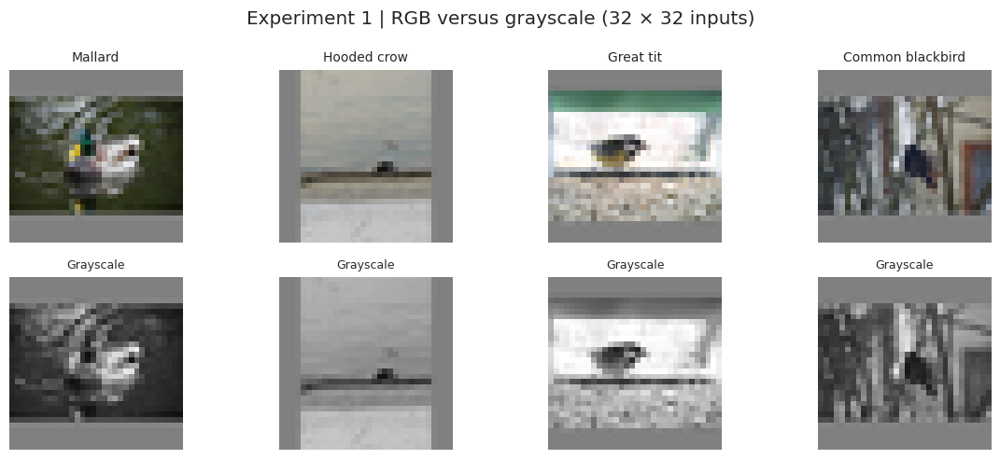

In [ ]:
GS_SIZE = 32
GS_K = 4
GS_MODEL_CFG = dict(filters=(32, 64, 128, 128), aug=True)

# --- Load RGB images -------------------------------------------------
def gs_load_rgb(fname, size=GS_SIZE):
    with Image.open(IMG_DIR / fname) as img:
        img = img.convert("RGB")
        s = max(img.size)

        canvas = Image.new("RGB", (s, s), (128, 128, 128))
        canvas.paste(
            img,
            ((s - img.width) // 2, (s - img.height) // 2)
        )

        return np.asarray(
            canvas.resize((size, size), Image.LANCZOS),
            dtype=np.float32
        ) / 255.0

# Reuse existing images if available
if "Xall" in globals() and Xall.shape == (len(train_df), GS_SIZE, GS_SIZE, 3):
    gs_rgb = np.asarray(Xall, dtype=np.float32)
else:
    gs_rgb = np.stack([gs_load_rgb(f) for f in train_df["file"]])

# --- Convert RGB to grayscale ----------------------------------------
# Standard luminance transformation
gs_luma = (
    0.299 * gs_rgb[..., 0] +
    0.587 * gs_rgb[..., 1] +
    0.114 * gs_rgb[..., 2]
).astype(np.float32)

# Repeat grayscale values into 3 channels
gs_gray = np.repeat(gs_luma[..., None], 3, axis=-1)

# Labels and original cross-validation folds
gs_y = train_df["species"].map(
    {sp: i for i, sp in enumerate(SPECIES)}
).to_numpy()

gs_fold = train_df["fold"].to_numpy()

assert gs_rgb.shape == gs_gray.shape
print("RGB shape:", gs_rgb.shape)
print("Grayscale shape:", gs_gray.shape)

# --- CNN architecture ------------------------------------------------
def gs_build_cnn(n_classes, size=GS_SIZE,
                 filters=(32, 64, 128),
                 dropout=True, gap=False,
                 aug=False, lr=1e-3):

    m = keras.Sequential()
    m.add(layers.Input(shape=(size, size, 3)))

    if aug:
        m.add(layers.RandomFlip("horizontal"))
        m.add(layers.RandomTranslation(0.1, 0.1))

    for k, f in enumerate(filters):
        m.add(layers.Conv2D(f, (3, 3), padding="same"))
        m.add(layers.LeakyReLU(negative_slope=0.1))
        m.add(layers.MaxPooling2D((2, 2)))

        if dropout:
            rate = 0.25 if k < len(filters) - 1 else 0.5
            m.add(layers.Dropout(rate))

    if gap:
        m.add(layers.GlobalAveragePooling2D())
    else:
        m.add(layers.Flatten())

    m.add(layers.Dense(128))
    m.add(layers.LeakyReLU(negative_slope=0.1))

    if dropout:
        m.add(layers.Dropout(0.3))

    m.add(layers.Dense(n_classes, activation="softmax"))

    m.compile(
        loss="sparse_categorical_crossentropy",
        optimizer=keras.optimizers.Adam(lr),
        metrics=["accuracy"]
    )
    return m

# --- Display RGB vs grayscale ----------------------------------------
fig, axs = plt.subplots(2, GS_K, figsize=(12, 5))

for j, sp in enumerate(SPECIES[:GS_K]):
    i = train_df.index[train_df["species"] == sp][0]

    axs[0, j].imshow(gs_rgb[i], interpolation="nearest")
    axs[0, j].set_title(EXP_SHORT_NAMES.get(sp, sp), fontsize=10)

    axs[1, j].imshow(gs_gray[i], vmin=0, vmax=1, interpolation="nearest")
    axs[1, j].set_title("Grayscale", fontsize=9)

    for row in range(2):
        axs[row, j].axis("off")

plt.suptitle("Experiment 1 | RGB versus grayscale (32 × 32 inputs)")
plt.tight_layout()
plt.show()


### 6.1.3 CNN training and cross-validation

Two CNNs are fitted for each of the five assessment folds and two random seeds: one using RGB inputs and one using grayscale inputs. Both use the common four-block architecture, geometric augmentation and early-stopping protocol. After fitting, each model is assessed both on the representation used for training and on the alternative representation. This yields **20 fitted CNNs and 40 assessment scores**. The model weights are not retrained for the cross-representation assessments.


In [ ]:

# --- Experimental settings --------------------------------------------
#GS_TEST_FOLDS = (0, 1)
GS_TEST_FOLDS = tuple(range(5))
GS_SEEDS = (0, 1)

gs_images = {
    "RGB": gs_rgb,
    "Grayscale": gs_gray
}

gs_idx = np.where(
    train_df["species"].isin(SPECIES[:GS_K]).to_numpy()
)[0]

gs_rows = []
gs_predictions = []

# --- Cross-validation -------------------------------------------------
for test_fold in GS_TEST_FOLDS:

    te = gs_idx[gs_fold[gs_idx] == test_fold]
    va = gs_idx[gs_fold[gs_idx] == (test_fold + 1) % 5]
    tr = gs_idx[
        ~np.isin(gs_fold[gs_idx],
                 [test_fold, (test_fold + 1) % 5])
    ]

    assert len(tr) and len(va) and len(te)

    for seed in GS_SEEDS:

        for train_colour, X_train in gs_images.items():

            keras.backend.clear_session()
            keras.utils.set_random_seed(seed)

            model = gs_build_cnn(GS_K, **GS_MODEL_CFG)

            es = keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=8,
                restore_best_weights=True
            )

            t0 = time.time()

            model.fit(
                X_train[tr],
                gs_y[tr],
                batch_size=50,
                epochs=50,
                validation_data=(X_train[va], gs_y[va]),
                callbacks=[es],
                verbose=0
            )

            # Evaluate on both image representations
            for test_colour, X_test in gs_images.items():

                pred = model.predict(
                    X_test[te], verbose=0
                ).argmax(axis=1)

                gs_rows.append({
                    "train": train_colour,
                    "test": test_colour,
                    "fold": test_fold,
                    "seed": seed,
                    "macro_f1": f1_score(
                        gs_y[te], pred,
                        average="macro",
                        labels=list(range(GS_K)),
                        zero_division=0
                    ),
                    "balanced_accuracy": balanced_accuracy_score(
                        gs_y[te], pred
                    )
                })

                gs_predictions.append({
                    "train": train_colour,
                    "test": test_colour,
                    "fold": test_fold,
                    "seed": seed,
                    "indices": te.copy(),
                    "pred": pred.copy()
                })

            print(
                f"Fold {test_fold}, seed {seed}, "
                f"trained on {train_colour}: "
                f"{time.time() - t0:.0f} s"
            )

# --- Save results ------------------------------------------------------
gs_results = pd.DataFrame(gs_rows)

gs_results.to_csv(
    "grayscale_comparison.csv",
    index=False
)

print("\nTraining completed!")


Fold 0, seed 0, trained on RGB: 15 s
Fold 0, seed 0, trained on Grayscale: 16 s
Fold 0, seed 1, trained on RGB: 16 s
Fold 0, seed 1, trained on Grayscale: 15 s
Fold 1, seed 0, trained on RGB: 13 s
Fold 1, seed 0, trained on Grayscale: 15 s
Fold 1, seed 1, trained on RGB: 14 s
Fold 1, seed 1, trained on Grayscale: 13 s
Fold 2, seed 0, trained on RGB: 21 s
Fold 2, seed 0, trained on Grayscale: 18 s
Fold 2, seed 1, trained on RGB: 14 s
Fold 2, seed 1, trained on Grayscale: 15 s
Fold 3, seed 0, trained on RGB: 18 s
Fold 3, seed 0, trained on Grayscale: 18 s
Fold 3, seed 1, trained on RGB: 15 s
Fold 3, seed 1, trained on Grayscale: 14 s
Fold 4, seed 0, trained on RGB: 16 s
Fold 4, seed 0, trained on Grayscale: 20 s
Fold 4, seed 1, trained on RGB: 22 s
Fold 4, seed 1, trained on Grayscale: 21 s

Training completed!


### 6.1.4 Results and visualisation

The first figure compares macro-F1 across the four train–assessment combinations; individual points represent assessment fold–seed combinations, and the larger markers show mean ± standard deviation. The second figure displays **paired changes** in macro-F1. The final heatmap compares species-level F1 for the four conditions. The matched RGB and grayscale models address the contribution of colour; the two unmatched conditions quantify sensitivity to representation shift.

Macro-F1 and balanced accuracy, grouped CV assessment:
    train      test  mean_f1  sd_f1  mean_bal_acc  runs
      RGB       RGB    0.544  0.051         0.555    10
      RGB Grayscale    0.511  0.063         0.528    10
Grayscale       RGB    0.504  0.042         0.517    10
Grayscale Grayscale    0.532  0.042         0.539    10


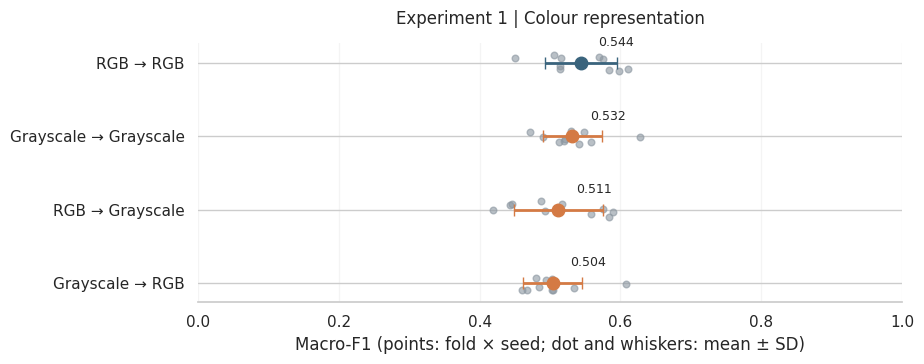


Paired macro-F1 changes (same fold and seed):
                             mean     sd
Grayscale vs RGB (matched) -0.012  0.042
RGB → Grayscale (shift)    -0.032  0.022
Grayscale → RGB (shift)    -0.028  0.017


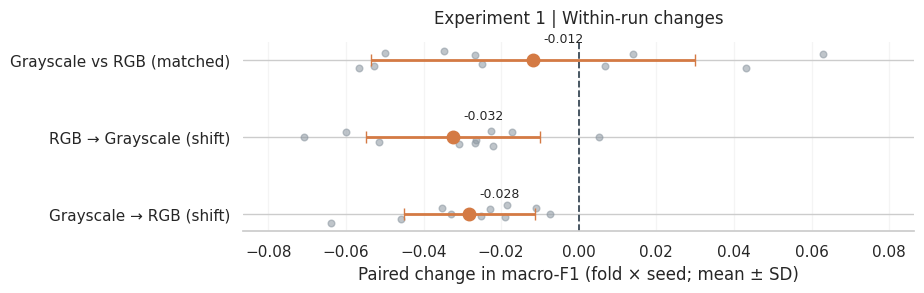


Mean per-species F1 across fold×seed assessments:
condition           RGB → RGB  Grayscale → Grayscale  RGB → Grayscale  Grayscale → RGB
species                                                                               
Anas platyrhynchos      0.584                  0.568            0.553            0.541
Corvus cornix           0.439                  0.423            0.353            0.402
Parus major             0.601                  0.610            0.592            0.563
Turdus merula           0.550                  0.526            0.548            0.509


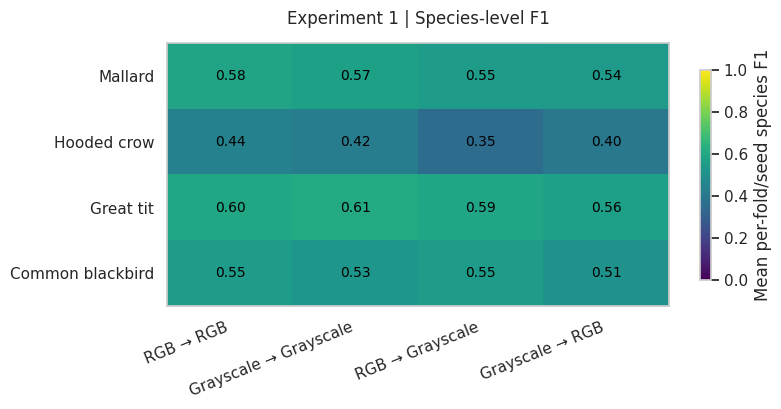

In [ ]:
# Experiment 1: fold×seed results and paired comparisons
GS_ORDER = [("RGB", "RGB"), ("Grayscale", "Grayscale"),
            ("RGB", "Grayscale"), ("Grayscale", "RGB")]
GS_LABELS = ["RGB → RGB (baseline)", "Grayscale → Grayscale",
             "RGB → Grayscale", "Grayscale → RGB"]

gs_results["condition"] = gs_results["train"] + " → " + gs_results["test"]
gs_summary = (gs_results.groupby(["train", "test"], sort=False)
              .agg(mean_f1=("macro_f1", "mean"),
                   sd_f1=("macro_f1", "std"),
                   mean_bal_acc=("balanced_accuracy", "mean"),
                   runs=("macro_f1", "size")).reset_index())
print("Macro-F1 and balanced accuracy, grouped CV assessment:")
print(gs_summary.round(3).to_string(index=False))

exp_plot_scores(gs_results, "condition",
    [f"{a} → {b}" for a,b in GS_ORDER],
    "Experiment 1 | Colour representation", "exp1_performance.png")

gs_paired = gs_results.pivot(index=["fold", "seed"],
                             columns=["train", "test"], values="macro_f1")
gs_deltas = pd.DataFrame({
    "Grayscale vs RGB (matched)": gs_paired[("Grayscale", "Grayscale")] - gs_paired[("RGB", "RGB")],
    "RGB → Grayscale (shift)": gs_paired[("RGB", "Grayscale")] - gs_paired[("RGB", "RGB")],
    "Grayscale → RGB (shift)": gs_paired[("Grayscale", "RGB")] - gs_paired[("Grayscale", "Grayscale")],
})
print("\nPaired macro-F1 changes (same fold and seed):")
print(pd.DataFrame({"mean": gs_deltas.mean(), "sd": gs_deltas.std()}).round(3))
exp_plot_deltas(gs_deltas, "Experiment 1 | Within-run changes",
                "exp1_paired_changes.png")

gs_species_df = exp_species_f1(gs_predictions, gs_y, ["train", "test"])
gs_species_df["condition"] = gs_species_df["train"] + " → " + gs_species_df["test"]
gs_species_table = (gs_species_df.groupby(["species","condition"])["f1"].mean()
                    .unstack("condition").reindex(index=SPECIES[:GS_K],
                      columns=[f"{a} → {b}" for a,b in GS_ORDER]))
print("\nMean per-species F1 across fold×seed assessments:")
print(gs_species_table.round(3).to_string())
exp_plot_species(gs_species_table, "Experiment 1 | Species-level F1",
                 "exp1_species_f1.png")
gs_summary.to_csv(EXP_OUT/"exp1_summary.csv", index=False)
gs_deltas.reset_index().to_csv(EXP_OUT/"exp1_paired_changes.csv", index=False)
gs_species_df.to_csv(EXP_OUT/"exp1_species_f1_by_run.csv", index=False)


### 6.1.5 Discussion and limitations

With training and assessment representations matched, **RGB → RGB** achieved **0.544 ± 0.051** macro-F1 (mean ± SD across ten fold–seed assessments), compared with **0.532 ± 0.042** for **Grayscale → Grayscale**. The paired grayscale-minus-RGB change was **−0.012 ± 0.042**. Retaining colour therefore provided a small advantage on average, but the paired variation was larger than the mean difference. This does not establish that colour is necessary for every species or photograph.

A representation change *at assessment only* led to larger losses. **RGB → Grayscale** achieved **0.511 ± 0.063**, a paired change of **−0.032 ± 0.022** relative to RGB → RGB; **Grayscale → RGB** achieved **0.504 ± 0.042**, a paired change of **−0.028 ± 0.017** relative to Grayscale → Grayscale. The consistent drop in both directions indicates that **keeping the training and assessment image representations consistent is more important here than the small average difference between the two matched representations**.

Species-level results were not uniform. Under matched RGB, mean F1 was **0.584** for Mallard, **0.439** for Hooded Crow, **0.601** for Great Tit and **0.550** for Common Blackbird. Grayscale slightly increased Great Tit F1 (**0.610**) but reduced the mean for the other three species (**0.568**, **0.423** and **0.526**, respectively). Hooded Crow was the most difficult of the four species in both matched conditions. These comparisons describe this CNN, the chosen luminance conversion and the available photographer-grouped folds; the fold–seed assessments are not independent replicates, and no significance test was conducted.

# 6.2 Random Colour Augmentation

### 6.2.1 Objective and experimental design

This experiment evaluates whether random changes in illumination and contrast during training improve recognition of unmodified bird photographs. Four configurations are compared at **32 × 32** pixels:

| Configuration | Additional training-time augmentation |
|---|---|
| Baseline | None |
| Brightness | Random brightness adjustment, factor 0.2 |
| Contrast | Random contrast adjustment, factor 0.2 |
| Brightness + Contrast | Both random adjustments |

Horizontal flipping and translation are included in **all four configurations**. The extra colour transformations are applied only during fitting; validation and assessment use the original RGB images. Consequently, this experiment measures the additional contribution of stochastic colour augmentation, not deterministic image enhancement.

### 6.2.2 Augmentation examples

The preview illustrates possible augmented appearances of the same training images. Previews are rendered at **128 × 128** for visibility, whereas the CNN input remains **32 × 32**. Because augmentation is random, each preview is one illustration rather than a fixed transformation of the dataset.


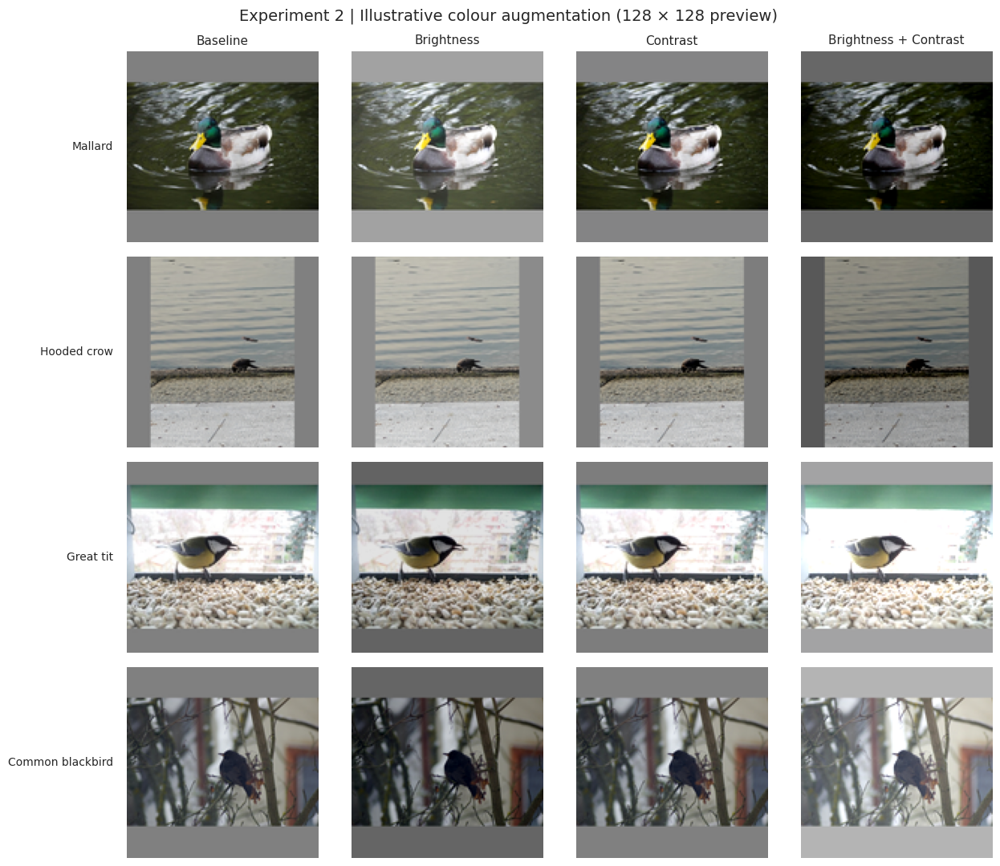

Dataset shape: (1591, 32, 32, 3)
Species: ['Anas platyrhynchos', 'Corvus cornix', 'Parus major', 'Turdus merula']


In [ ]:

# --- Experiment settings -------------------------------------------
CA_SIZE = 32
CA_K = 4

CA_BRIGHTNESS = 0.2
CA_CONTRAST = 0.2

CA_CONFIGS = (
    "Baseline",
    "Brightness",
    "Contrast",
    "Brightness + Contrast"
)

# --- Load RGB images ------------------------------------------------
# Same preprocessing as the original notebook
def ca_load_rgb(fname, size=CA_SIZE):
    with Image.open(IMG_DIR / fname) as im:
        im = im.convert("RGB")
        s = max(im.size)

        canvas = Image.new("RGB", (s, s), (128, 128, 128))
        canvas.paste(
            im,
            ((s - im.width) // 2, (s - im.height) // 2)
        )

        return np.asarray(
            canvas.resize((size, size), Image.LANCZOS),
            dtype=np.float32
        ) / 255.0

# Reuse previously loaded RGB images if available
expected_shape = (len(train_df), CA_SIZE, CA_SIZE, 3)

if "gs_rgb" in globals() and gs_rgb.shape == expected_shape:
    ca_rgb = gs_rgb
elif "Xall" in globals() and Xall.shape == expected_shape:
    ca_rgb = Xall
else:
    ca_rgb = np.stack([
        ca_load_rgb(f) for f in train_df["file"]
    ])

ca_y = train_df["species"].map(
    {sp: i for i, sp in enumerate(SPECIES)}
).to_numpy()

ca_fold = train_df["fold"].to_numpy()

# --- Colour augmentation layers ------------------------------------
def ca_colour_layers(setting):
    transforms = []

    if setting in ("Brightness", "Brightness + Contrast"):
        transforms.append(
            layers.RandomBrightness(
                factor=CA_BRIGHTNESS,
                value_range=(0, 1)
            )
        )

    if setting in ("Contrast", "Brightness + Contrast"):
        transforms.append(
            layers.RandomContrast(
                factor=CA_CONTRAST,
                value_range=(0, 1)
            )
        )

    return transforms

# --- CNN architecture -----------------------------------------------
# Same architecture as the original combined CNN
def ca_build_cnn(n_classes, setting):

    model = keras.Sequential()
    model.add(layers.Input(shape=(CA_SIZE, CA_SIZE, 3)))

    # Original geometric augmentation
    model.add(layers.RandomFlip("horizontal"))
    model.add(layers.RandomTranslation(0.1, 0.1))

    # Additional colour augmentation
    for transform in ca_colour_layers(setting):
        model.add(transform)

    # Original four convolutional blocks
    for k, filters in enumerate((32, 64, 128, 128)):
        model.add(
            layers.Conv2D(filters, (3, 3), padding="same")
        )
        model.add(layers.LeakyReLU(negative_slope=0.1))
        model.add(layers.MaxPooling2D((2, 2)))
        model.add(
            layers.Dropout(0.25 if k < 3 else 0.5)
        )

    model.add(layers.Flatten())
    model.add(layers.Dense(128))
    model.add(layers.LeakyReLU(negative_slope=0.1))
    model.add(layers.Dropout(0.3))
    model.add(layers.Dense(n_classes, activation="softmax"))

    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

# --- Visual demonstration -------------------------------------------
keras.utils.set_random_seed(10)

fig, axs = plt.subplots(
    CA_K, len(CA_CONFIGS),
    figsize=(13, 11)
)

for r, sp in enumerate(SPECIES[:CA_K]):

    fname = train_df.loc[train_df["species"] == sp, "file"].iloc[0]

    # Larger preview for visualization only
    img = ca_load_rgb(fname, size=128)

    for c, setting in enumerate(CA_CONFIGS):

        if setting == "Baseline":
            transformed = img
        else:
            aug = keras.Sequential(ca_colour_layers(setting))

            transformed = aug(
                tf.convert_to_tensor(img[None, ...]),
                training=True
            ).numpy()[0]

        axs[r, c].imshow(
            np.clip(transformed, 0, 1)
        )
        axs[r, c].axis("off")

        if r == 0:
            axs[r, c].set_title(setting, fontsize=11)

    axs[r, 0].text(-0.07, 0.5, EXP_SHORT_NAMES.get(sp, sp), ha="right", va="center", transform=axs[r, 0].transAxes, fontsize=10)

plt.suptitle(
    "Experiment 2 | Illustrative colour augmentation (128 × 128 preview)",
    fontsize=14
)
plt.tight_layout()
plt.show()

print("Dataset shape:", ca_rgb.shape)
print("Species:", SPECIES[:CA_K])


### 6.2.3 CNN training and cross-validation

The same five group-preserving assessment folds and two training seeds are used for all four augmentation strategies. Each model follows the common architecture, optimizer and early-stopping protocol. The design contains **4 configurations × 5 folds × 2 seeds = 40 CNN fits**. All fitted models are assessed on the **same unmodified RGB images** within their corresponding assessment fold, enabling fold-and-seed-paired comparisons against the baseline.


In [ ]:
# --- Experimental settings ------------------------------------------
CA_TEST_FOLDS = tuple(range(5))
CA_SEEDS = (0, 1)

ca_idx = np.where(
    train_df["species"].isin(SPECIES[:CA_K]).to_numpy()
)[0]

ca_rows = []
ca_predictions = []

# --- Train models ----------------------------------------------------
for test_fold in CA_TEST_FOLDS:

    te = ca_idx[ca_fold[ca_idx] == test_fold]

    va = ca_idx[
        ca_fold[ca_idx] == (test_fold + 1) % 5
    ]

    tr = ca_idx[
        ~np.isin(
            ca_fold[ca_idx],
            [test_fold, (test_fold + 1) % 5]
        )
    ]

    assert len(tr) and len(va) and len(te)

    for seed in CA_SEEDS:

        for setting in CA_CONFIGS:

            keras.backend.clear_session()
            keras.utils.set_random_seed(seed)

            model = ca_build_cnn(CA_K, setting)

            early_stop = keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=8,
                restore_best_weights=True
            )

            t0 = time.time()

            history = model.fit(
                ca_rgb[tr],
                ca_y[tr],
                batch_size=50,
                epochs=50,
                validation_data=(
                    ca_rgb[va],
                    ca_y[va]
                ),
                callbacks=[early_stop],
                verbose=0
            )

            # Test on original RGB images
            pred = model.predict(
                ca_rgb[te],
                verbose=0
            ).argmax(axis=1)

            macro_f1 = f1_score(
                ca_y[te],
                pred,
                average="macro",
                labels=list(range(CA_K)),
                zero_division=0
            )

            bal_acc = balanced_accuracy_score(
                ca_y[te], pred
            )

            ca_rows.append({
                "setting": setting,
                "fold": test_fold,
                "seed": seed,
                "macro_f1": macro_f1,
                "balanced_accuracy": bal_acc,
                "epochs": len(history.history["loss"]),
                "time_seconds": time.time() - t0
            })

            ca_predictions.append({
                "setting": setting,
                "fold": test_fold,
                "seed": seed,
                "indices": te.copy(),
                "pred": pred.copy()
            })

            print(
                f"Fold {test_fold} | Seed {seed} | "
                f"{setting:24s} | "
                f"F1 = {macro_f1:.3f} | "
                f"Epochs = {len(history.history['loss'])}"
            )

# --- Save results ----------------------------------------------------
ca_results = pd.DataFrame(ca_rows)

ca_results.to_csv(
    "colour_augmentation_results.csv",
    index=False
)

print("\nTraining completed!")

Fold 0 | Seed 0 | Baseline                 | F1 = 0.514 | Epochs = 33
Fold 0 | Seed 0 | Brightness               | F1 = 0.265 | Epochs = 15
Fold 0 | Seed 0 | Contrast                 | F1 = 0.255 | Epochs = 15
Fold 0 | Seed 0 | Brightness + Contrast    | F1 = 0.520 | Epochs = 50
Fold 0 | Seed 1 | Baseline                 | F1 = 0.506 | Epochs = 41
Fold 0 | Seed 1 | Brightness               | F1 = 0.480 | Epochs = 40
Fold 0 | Seed 1 | Contrast                 | F1 = 0.530 | Epochs = 36
Fold 0 | Seed 1 | Brightness + Contrast    | F1 = 0.510 | Epochs = 45
Fold 1 | Seed 0 | Baseline                 | F1 = 0.450 | Epochs = 29
Fold 1 | Seed 0 | Brightness               | F1 = 0.481 | Epochs = 29
Fold 1 | Seed 0 | Contrast                 | F1 = 0.509 | Epochs = 50
Fold 1 | Seed 0 | Brightness + Contrast    | F1 = 0.543 | Epochs = 41
Fold 1 | Seed 1 | Baseline                 | F1 = 0.515 | Epochs = 34
Fold 1 | Seed 1 | Brightness               | F1 = 0.520 | Epochs = 32
Fold 1 | Seed 1 | Co

### 6.2.4 Results and visualisation

The performance plot presents mean ± SD and the individual macro-F1 scores for each configuration. Paired differences subtract the baseline score from each augmentation score **within the same fold and seed**, providing a direct assessment of the direction and stability of any gain. A species-level heatmap identifies variation in augmentation effects between the four species. Balanced accuracy and the number of training epochs are reported as supporting measures.


Experiment 2 | Grouped-CV summary:
                       mean_f1  sd_f1  mean_bal_acc  mean_epochs  runs
setting                                                               
Baseline                 0.544  0.051         0.555         39.4    10
Brightness               0.513  0.099         0.533         39.0    10
Contrast                 0.513  0.100         0.534         38.4    10
Brightness + Contrast    0.546  0.031         0.559         40.8    10


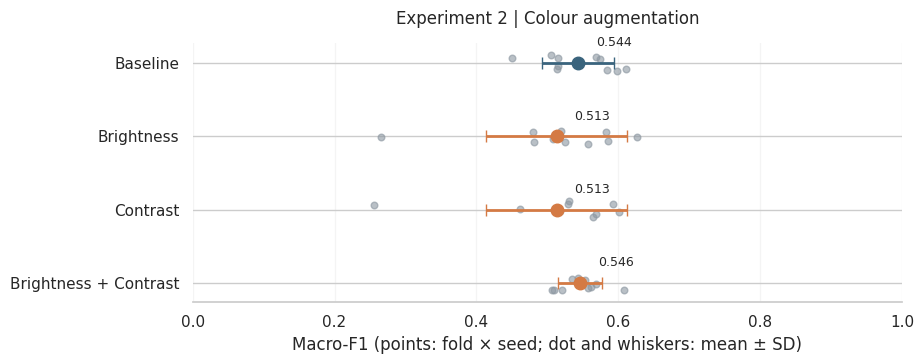


Paired differences from baseline:
                        mean     sd
setting                            
Brightness            -0.031  0.086
Contrast              -0.031  0.097
Brightness + Contrast  0.003  0.042


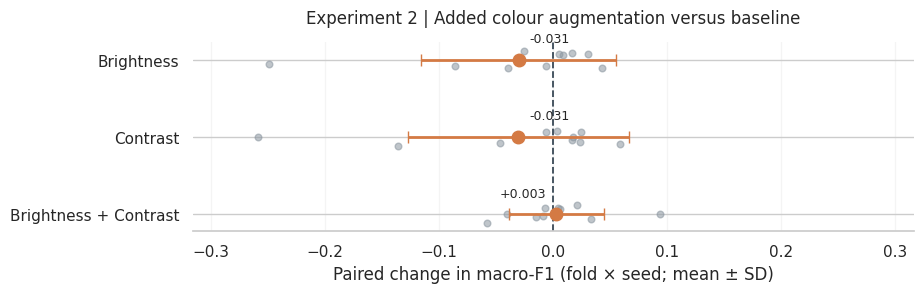


Mean per-species F1 (5 assessment folds × 2 seeds):
setting             Baseline  Brightness  Contrast  Brightness + Contrast
species                                                                  
Anas platyrhynchos     0.584       0.584     0.604                  0.611
Corvus cornix          0.439       0.431     0.417                  0.463
Parus major            0.601       0.583     0.577                  0.593
Turdus merula          0.550       0.455     0.455                  0.518


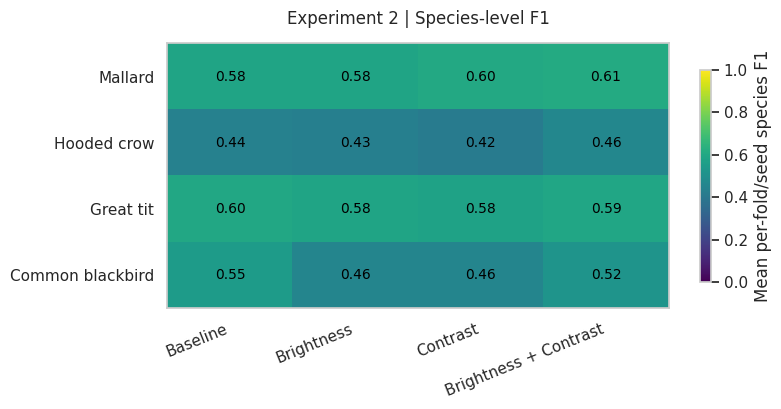

In [ ]:
# Experiment 2: performance and paired augmentation gains
ca_summary = (ca_results.groupby("setting")
    .agg(mean_f1=("macro_f1", "mean"), sd_f1=("macro_f1", "std"),
         mean_bal_acc=("balanced_accuracy", "mean"),
         mean_epochs=("epochs", "mean"), runs=("macro_f1", "size"))
    .reindex(CA_CONFIGS))
print("Experiment 2 | Grouped-CV summary:")
print(ca_summary.round(3).to_string())
exp_plot_scores(ca_results, "setting", CA_CONFIGS,
    "Experiment 2 | Colour augmentation", "exp2_performance.png")

ca_paired = ca_results.pivot(index=["fold", "seed"],
                              columns="setting", values="macro_f1")
ca_differences = ca_paired[list(CA_CONFIGS[1:])].sub(
    ca_paired["Baseline"], axis=0
)
print("\nPaired differences from baseline:")
print(pd.DataFrame({"mean":ca_differences.mean(),"sd":ca_differences.std()}).round(3))
exp_plot_deltas(ca_differences,
    "Experiment 2 | Added colour augmentation versus baseline",
    "exp2_paired_changes.png", order=CA_CONFIGS[1:])

ca_species_df=exp_species_f1(ca_predictions, ca_y, ["setting"])
ca_species_table=(ca_species_df.groupby(["species","setting"])["f1"].mean()
    .unstack("setting").reindex(index=SPECIES[:CA_K],columns=CA_CONFIGS))
print("\nMean per-species F1 (5 assessment folds × 2 seeds):")
print(ca_species_table.round(3).to_string())
exp_plot_species(ca_species_table,"Experiment 2 | Species-level F1",
                 "exp2_species_f1.png")
ca_summary.to_csv(EXP_OUT/"exp2_summary.csv")
ca_differences.reset_index().to_csv(EXP_OUT/"exp2_paired_changes.csv",index=False)
ca_species_df.to_csv(EXP_OUT/"exp2_species_f1_by_run.csv",index=False)

### 6.2.5 Discussion and limitations

The baseline without additional colour augmentation achieved **0.544 ± 0.051** macro-F1. **Brightness + Contrast** had the highest mean, at **0.546 ± 0.031**, while **Brightness** and **Contrast** each averaged **0.513**, with SDs of **0.099** and **0.100**, respectively. Paired against the baseline within each fold and seed, the mean differences were **+0.003 ± 0.042** for Brightness + Contrast, **−0.031 ± 0.086** for Brightness and **−0.031 ± 0.097** for Contrast.

Consequently, **adding both transformations was approximately neutral on average**, rather than showing a convincing improvement over the baseline. Using brightness or contrast adjustment alone reduced the mean score and yielded more variable results. Since Brightness + Contrast had the highest mean among the *additional augmentation* strategies, it was selected as the Experiment 2 candidate for the final held-out evaluation. Its advantage over the unaugmented baseline was, however, only about **0.003 macro-F1** in cross-validation.

Effects differed across species. Relative to the baseline, Brightness + Contrast improved mean F1 for **Mallard** (**0.584 → 0.611**) and **Hooded Crow** (**0.439 → 0.463**), but reduced it for **Great Tit** (**0.601 → 0.593**) and **Common Blackbird** (**0.550 → 0.518**). The random adjustment factors were fixed at **0.2**, and the fold–seed variation prevents strong claims about general improvements. The results do not imply that other colour-augmentation strengths or policies would have the same effect.

# 6.3 Deterministic Image Enhancement at Fixed Resolution

### 6.3.1 Objective and experimental design

This experiment examines whether enhancing image luminance improves bird-species classification when the input resolution remains fixed at **32 × 32 pixels**. Four image-preparation strategies are evaluated:

| Method | Processing operation |
|---|---|
| Original RGB | No luminance enhancement (reference) |
| Fixed Contrast | Multiply deviations from mean LAB lightness by 1.3 |
| Histogram Equalization | Global equalization of LAB lightness |
| CLAHE | Contrast-limited adaptive equalization of LAB lightness (clip limit 2.0; 8 × 8 tile grid) |

All enhancement operations are deterministic, applied to the full-resolution photograph **before padding and resizing**, and used consistently for fitting, validation and assessment. Unlike the training-time augmentation in Experiment 2, each method changes the representation presented at every stage of learning.

### 6.3.2 Enhancement examples

For visual comparison, the same images are shown under all four preprocessing methods at **128 × 128**. This display resolution is not part of the statistical comparison: **all models in Experiment 3 use 32 × 32 inputs**.

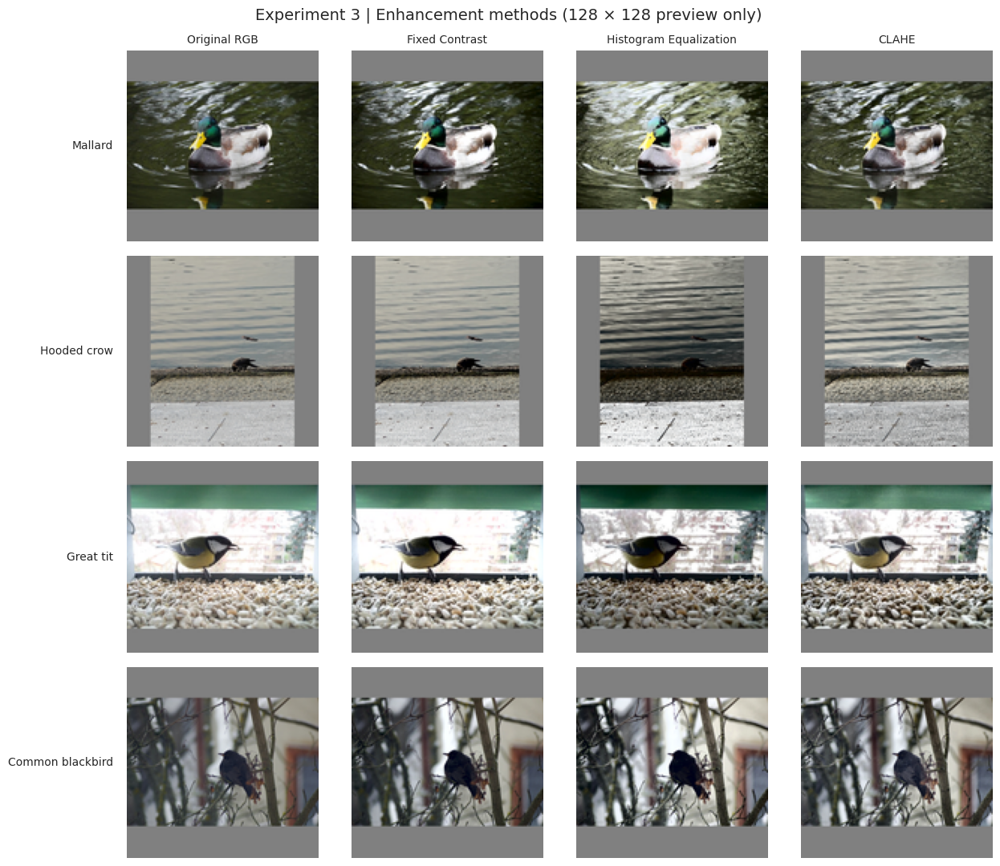

Preparing Original RGB images...
Original RGB (1591, 32, 32, 3)
Preparing Fixed Contrast images...
Fixed Contrast (1591, 32, 32, 3)
Preparing Histogram Equalization images...
Histogram Equalization (1591, 32, 32, 3)
Preparing CLAHE images...
CLAHE (1591, 32, 32, 3)

All image datasets prepared!


In [ ]:
# --- Experiment settings --------------------------------------------
EH_SIZE = 32
EH_K = 4

EH_CONTRAST_FACTOR = 1.3
EH_CLAHE_CLIP = 2.0
EH_CLAHE_GRID = (8, 8)

EH_CONFIGS = (
    "Original RGB",
    "Fixed Contrast",
    "Histogram Equalization",
    "CLAHE"
)

# --- Define image enhancement ---------------------------------------
def eh_enhance(im, method):

    im = im.convert("RGB")

    if method == "Original RGB":
        return im

    rgb = np.asarray(im, dtype=np.uint8)

    # Convert RGB to LAB
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)

    # Extract luminance channel
    L, A, B = cv2.split(lab)

    if method == "Fixed Contrast":

        # Increase contrast around mean luminance
        mean_L = L.mean()

        L = np.clip(
            (L.astype(np.float32) - mean_L)
            * EH_CONTRAST_FACTOR + mean_L,
            0, 255
        ).astype(np.uint8)

    elif method == "Histogram Equalization":

        # Global histogram equalization
        L = cv2.equalizeHist(L)

    elif method == "CLAHE":

        # Contrast Limited Adaptive Histogram Equalization
        clahe = cv2.createCLAHE(
            clipLimit=EH_CLAHE_CLIP,
            tileGridSize=EH_CLAHE_GRID
        )

        L = clahe.apply(L)

    else:
        raise ValueError(f"Unknown method: {method}")

    # Recombine LAB channels and convert back to RGB
    enhanced_lab = cv2.merge((L, A, B))

    enhanced_rgb = cv2.cvtColor(
        enhanced_lab,
        cv2.COLOR_LAB2RGB
    )

    return Image.fromarray(enhanced_rgb)


# --- Load image: enhance before resizing ----------------------------
def eh_load_img(fname, method="Original RGB", size=EH_SIZE):

    with Image.open(IMG_DIR / fname) as original:

        im = eh_enhance(original, method)

        # Preserve aspect ratio using original grey padding
        s = max(im.size)

        canvas = Image.new(
            "RGB",
            (s, s),
            (128, 128, 128)
        )

        canvas.paste(
            im,
            (
                (s - im.width) // 2,
                (s - im.height) // 2
            )
        )

        resized = canvas.resize(
            (size, size),
            Image.Resampling.LANCZOS
        )

        return (
            np.asarray(resized, dtype=np.float32) / 255.0
        )


# --- Display enhancement examples -----------------------------------
fig, axs = plt.subplots(
    EH_K,
    len(EH_CONFIGS),
    figsize=(13, 11)
)

for r, sp in enumerate(SPECIES[:EH_K]):

    fname = train_df.loc[
        train_df["species"] == sp, "file"
    ].iloc[0]

    for c, method in enumerate(EH_CONFIGS):

        # Use 128x128 for visualization
        img = eh_load_img(
            fname, method=method, size=128
        )

        axs[r, c].imshow(img)
        axs[r, c].axis("off")

        if c == 0:
            axs[r,c].text(-0.07, 0.5, EXP_SHORT_NAMES.get(sp,sp), ha="right", va="center", transform=axs[r,c].transAxes, fontsize=10)

        if r == 0:
            axs[r, c].set_title(method, fontsize=10)

plt.suptitle(
    "Experiment 3 | Enhancement methods (128 × 128 preview only)",
    fontsize=14
)

plt.tight_layout()
plt.show()


# --- Prepare dataset for CNN training -------------------------------
eh_idx = np.where(
    train_df["species"].isin(SPECIES[:EH_K]).to_numpy()
)[0]

eh_sub = train_df.iloc[eh_idx].reset_index(drop=True)

eh_y = eh_sub["species"].map(
    {sp: i for i, sp in enumerate(SPECIES[:EH_K])}
).to_numpy()

eh_fold = eh_sub["fold"].to_numpy()

eh_images = {}

for method in EH_CONFIGS:

    print(f"Preparing {method} images...")

    # Reuse the original RGB images if already loaded
    if (
        method == "Original RGB"
        and "Xall" in globals()
        and Xall.shape == (len(train_df), EH_SIZE, EH_SIZE, 3)
    ):
        eh_images[method] = np.asarray(
            Xall[eh_idx], dtype=np.float32
        )

    else:
        eh_images[method] = np.stack([
            eh_load_img(f, method)
            for f in eh_sub["file"]
        ])

    print(method, eh_images[method].shape)

print("\nAll image datasets prepared!")


### 6.3.3 CNN training and cross-validation

The four methods are evaluated with the same five grouped assessment folds, two training seeds and common four-block CNN. For each fold, the next fold supplies the validation observations used for early stopping. Geometric augmentation is retained for every method. The experiment requires **4 methods × 5 folds × 2 seeds = 40 CNN fits**. Each model is assessed on photographs processed using its corresponding enhancement method.

In [ ]:
# --- CNN architecture -----------------------------------------------
def eh_build_cnn(n_classes):

    model = keras.Sequential()

    model.add(
        layers.Input(shape=(EH_SIZE, EH_SIZE, 3))
    )

    # Original geometric augmentation
    model.add(layers.RandomFlip("horizontal"))
    model.add(layers.RandomTranslation(0.1, 0.1))

    # Four convolutional blocks
    for k, filters in enumerate((32, 64, 128, 128)):

        model.add(
            layers.Conv2D(filters, (3, 3), padding="same")
        )
        model.add(layers.LeakyReLU(negative_slope=0.1))
        model.add(layers.MaxPooling2D((2, 2)))

        model.add(
            layers.Dropout(0.25 if k < 3 else 0.5)
        )

    model.add(layers.Flatten())
    model.add(layers.Dense(128))
    model.add(layers.LeakyReLU(negative_slope=0.1))
    model.add(layers.Dropout(0.3))

    model.add(
        layers.Dense(n_classes, activation="softmax")
    )

    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


# --- Experimental settings ------------------------------------------
EH_TEST_FOLDS = tuple(range(5))
EH_SEEDS = (0, 1)


eh_local_idx = np.arange(len(eh_sub))

eh_results_rows = []
eh_predictions = []

# --- CNN training ----------------------------------------------------
for test_fold in EH_TEST_FOLDS:

    te = eh_local_idx[
        eh_fold == test_fold
    ]

    va = eh_local_idx[
        eh_fold == (test_fold + 1) % 5
    ]

    tr = eh_local_idx[
        ~np.isin(
            eh_fold,
            [test_fold, (test_fold + 1) % 5]
        )
    ]

    assert len(tr) and len(va) and len(te)

    for seed in EH_SEEDS:

        for method in EH_CONFIGS:

            keras.backend.clear_session()
            keras.utils.set_random_seed(seed)

            X = eh_images[method]

            model = eh_build_cnn(EH_K)

            early_stop = keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=8,
                restore_best_weights=True
            )

            t0 = time.time()

            history = model.fit(
                X[tr],
                eh_y[tr],
                batch_size=50,
                epochs=50,
                validation_data=(
                    X[va],
                    eh_y[va]
                ),
                callbacks=[early_stop],
                verbose=0
            )

            # Test on the SAME enhancement type
            pred = model.predict(
                X[te],
                verbose=0
            ).argmax(axis=1)

            macro_f1 = f1_score(
                eh_y[te],
                pred,
                average="macro",
                labels=list(range(EH_K)),
                zero_division=0
            )

            bal_acc = balanced_accuracy_score(
                eh_y[te], pred
            )

            eh_results_rows.append({
                "method": method,
                "fold": test_fold,
                "seed": seed,
                "macro_f1": macro_f1,
                "balanced_accuracy": bal_acc,
                "epochs": len(history.history["loss"]),
                "time_seconds": time.time() - t0
            })

            eh_predictions.append({
                "method": method,
                "fold": test_fold,
                "seed": seed,
                "indices": te.copy(),
                "pred": pred.copy()
            })

            print(
                f"Fold {test_fold} | Seed {seed} | "
                f"{method:24s} | "
                f"F1 = {macro_f1:.3f} | "
                f"Epochs = {len(history.history['loss'])}"
            )

# --- Save results ----------------------------------------------------
eh_results = pd.DataFrame(eh_results_rows)

eh_results.to_csv(
    "image_enhancement_results.csv",
    index=False
)

print("\nImage enhancement experiment completed!")

Fold 0 | Seed 0 | Original RGB             | F1 = 0.514 | Epochs = 33
Fold 0 | Seed 0 | Fixed Contrast           | F1 = 0.474 | Epochs = 29
Fold 0 | Seed 0 | Histogram Equalization   | F1 = 0.437 | Epochs = 27
Fold 0 | Seed 0 | CLAHE                    | F1 = 0.538 | Epochs = 37
Fold 0 | Seed 1 | Original RGB             | F1 = 0.506 | Epochs = 41
Fold 0 | Seed 1 | Fixed Contrast           | F1 = 0.268 | Epochs = 13
Fold 0 | Seed 1 | Histogram Equalization   | F1 = 0.500 | Epochs = 34
Fold 0 | Seed 1 | CLAHE                    | F1 = 0.485 | Epochs = 39
Fold 1 | Seed 0 | Original RGB             | F1 = 0.450 | Epochs = 29
Fold 1 | Seed 0 | Fixed Contrast           | F1 = 0.489 | Epochs = 32
Fold 1 | Seed 0 | Histogram Equalization   | F1 = 0.544 | Epochs = 39
Fold 1 | Seed 0 | CLAHE                    | F1 = 0.519 | Epochs = 37
Fold 1 | Seed 1 | Original RGB             | F1 = 0.515 | Epochs = 34
Fold 1 | Seed 1 | Fixed Contrast           | F1 = 0.512 | Epochs = 31
Fold 1 | Seed 1 | Hi

### 6.3.4 Results and visualisation

The method comparison displays macro-F1 for each fold–seed assessment together with mean ± SD. Each enhancement's gain is calculated relative to Original RGB **within the same fold and seed**, avoiding comparisons between unrelated assessment partitions. Species-level F1 is averaged across the five folds and two seeds; a separate heatmap displays these class-specific results.

For enhancement method $m$, assessment fold $f$ and training seed $r$, the paired gain is

$$
\Delta_{m,f,r}=\mathrm{F1}_{m,f,r}-\mathrm{F1}_{\mathrm{RGB},f,r}.
$$


Experiment 3 | Grouped-CV summary (32 × 32):
                        mean_f1  sd_f1  mean_bal_acc  mean_epochs  runs
method                                                                 
Original RGB              0.544  0.051         0.555         39.4    10
Fixed Contrast            0.471  0.129         0.503         31.0    10
Histogram Equalization    0.515  0.058         0.534         37.8    10
CLAHE                     0.503  0.092         0.526         38.2    10


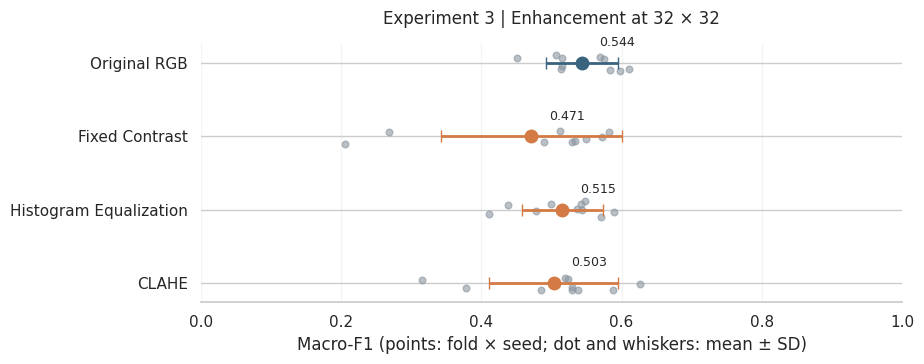


Paired macro-F1 change relative to original RGB:
                         mean     sd
method                              
Fixed Contrast         -0.072  0.138
Histogram Equalization -0.028  0.069
CLAHE                  -0.041  0.119


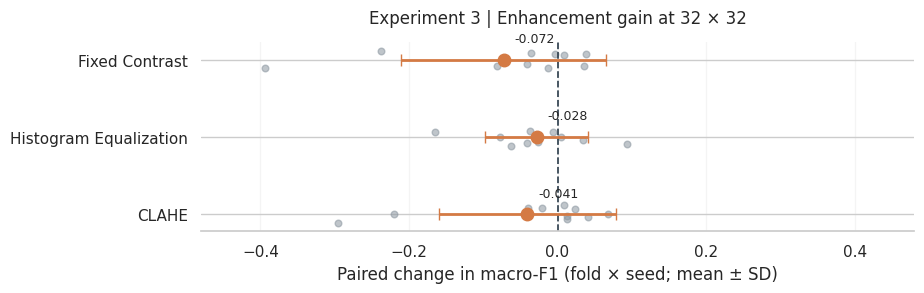


Mean per-species F1 (5 assessment folds × 2 seeds):
method              Original RGB  Fixed Contrast  Histogram Equalization  CLAHE
species                                                                        
Anas platyrhynchos         0.584           0.569                   0.576  0.609
Corvus cornix              0.439           0.341                   0.392  0.356
Parus major                0.601           0.504                   0.610  0.586
Turdus merula              0.550           0.471                   0.484  0.461


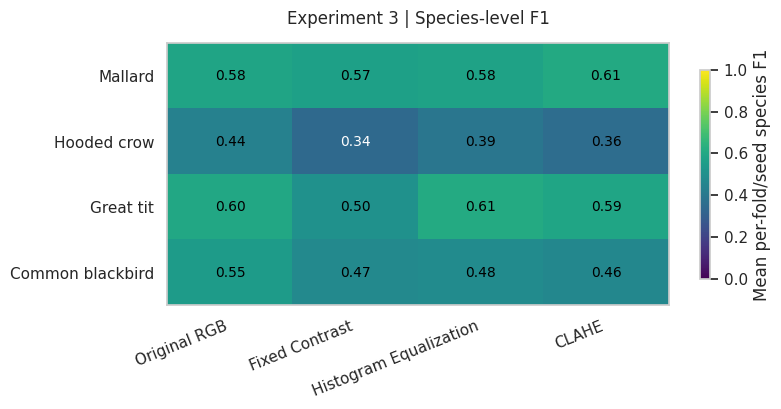

In [ ]:
# Experiment 3: fixed-resolution enhancement comparisons (32 × 32 only)
eh_summary=(eh_results.groupby("method")
    .agg(mean_f1=("macro_f1","mean"),sd_f1=("macro_f1","std"),
         mean_bal_acc=("balanced_accuracy","mean"),
         mean_epochs=("epochs","mean"),runs=("macro_f1","size"))
    .reindex(EH_CONFIGS))
print("Experiment 3 | Grouped-CV summary (32 × 32):")
print(eh_summary.round(3).to_string())
exp_plot_scores(eh_results,"method",EH_CONFIGS,
                "Experiment 3 | Enhancement at 32 × 32", "exp3_performance.png")

eh_paired=eh_results.pivot(index=["fold","seed"],
                           columns="method", values="macro_f1")
eh_differences=eh_paired[list(EH_CONFIGS[1:])].sub(eh_paired["Original RGB"],axis=0)
print("\nPaired macro-F1 change relative to original RGB:")
print(pd.DataFrame({"mean":eh_differences.mean(),"sd":eh_differences.std()}).round(3))
exp_plot_deltas(eh_differences,
    "Experiment 3 | Enhancement gain at 32 × 32",
    "exp3_paired_changes.png",order=EH_CONFIGS[1:])

eh_species_df=exp_species_f1(eh_predictions, eh_y, ["method"])
eh_species_table=(eh_species_df.groupby(["species","method"])["f1"].mean()
    .unstack("method").reindex(index=SPECIES[:EH_K],columns=EH_CONFIGS))
print("\nMean per-species F1 (5 assessment folds × 2 seeds):")
print(eh_species_table.round(3).to_string())
exp_plot_species(eh_species_table,"Experiment 3 | Species-level F1",
                 "exp3_species_f1.png")
eh_summary.to_csv(EXP_OUT/"exp3_summary.csv")
eh_differences.reset_index().to_csv(EXP_OUT/"exp3_paired_changes.csv",index=False)
eh_species_df.to_csv(EXP_OUT/"exp3_species_f1_by_run.csv",index=False)

### 6.3.5 Discussion and limitations

At **32 × 32**, the unenhanced **Original RGB** reference obtained **0.544 ± 0.051** macro-F1, the **highest mean of all four representations**. Each deterministic enhancement reduced average performance: **Fixed Contrast** achieved **0.471 ± 0.129**, **Histogram Equalization** **0.515 ± 0.058**, and **CLAHE** **0.503 ± 0.092**. Their paired changes from Original RGB were **−0.072 ± 0.138**, **−0.028 ± 0.069** and **−0.041 ± 0.119**, respectively.

The species-level comparison shows why an overall improvement cannot be assumed. Histogram Equalization slightly increased **Great Tit** F1 (**0.601 → 0.610**) but lowered **Mallard** (**0.584 → 0.576**), **Hooded Crow** (**0.439 → 0.392**) and **Common Blackbird** (**0.550 → 0.484**). CLAHE increased Mallard F1 to **0.609**, but its mean results for the other species were below the Original RGB reference. Thus, changes to luminance contrast can help some classes while harming others.

**Histogram Equalization was the best of the three enhancement alternatives**, despite performing worse than Original RGB overall. It was therefore retained as the Experiment 3 **non-baseline enhancement candidate** for the independent held-out test; this is not a claim that it was the best of all four representations. The enhancement parameters were not tuned, and the findings are limited to the specified transformations, **32 × 32** resolution and photographer-grouped folds. Experiment 4 examines whether their relative performance changes with image size.

# 6.4 Resolution and Enhancement Effects

### 6.4.1 Objective and experimental design

Experiment 4 investigates whether the benefit of image enhancement depends on input resolution. The four preprocessing methods from Experiment 3 are applied at **32 × 32**, **64 × 64** and **96 × 96** pixels, producing **12 resolution–method configurations**. In every case, enhancement is applied before grey padding and Lanczos resizing.

The primary comparison is the **change in macro-F1 relative to unenhanced RGB at the same resolution**. A secondary comparison examines whether this enhancement gain changes between 32 pixels and a higher resolution. This separates the effect of enhancement from the absolute performance of larger inputs more clearly than directly comparing enhanced scores across different sizes.

The model uses a `Flatten` layer before a dense classifier. Increasing resolution therefore changes the number of trainable parameters as well as the image detail available to the network. Resolution effects cannot be attributed exclusively to pixel information.

### 6.4.2 Visual comparison of resolution and enhancement

A single training photograph is displayed under all 12 combinations. The accompanying mean absolute pixel difference describes how much each transformation modifies this example relative to unenhanced RGB at the same resolution. It is a descriptive measure of image change, **not** a measure of predictive performance.


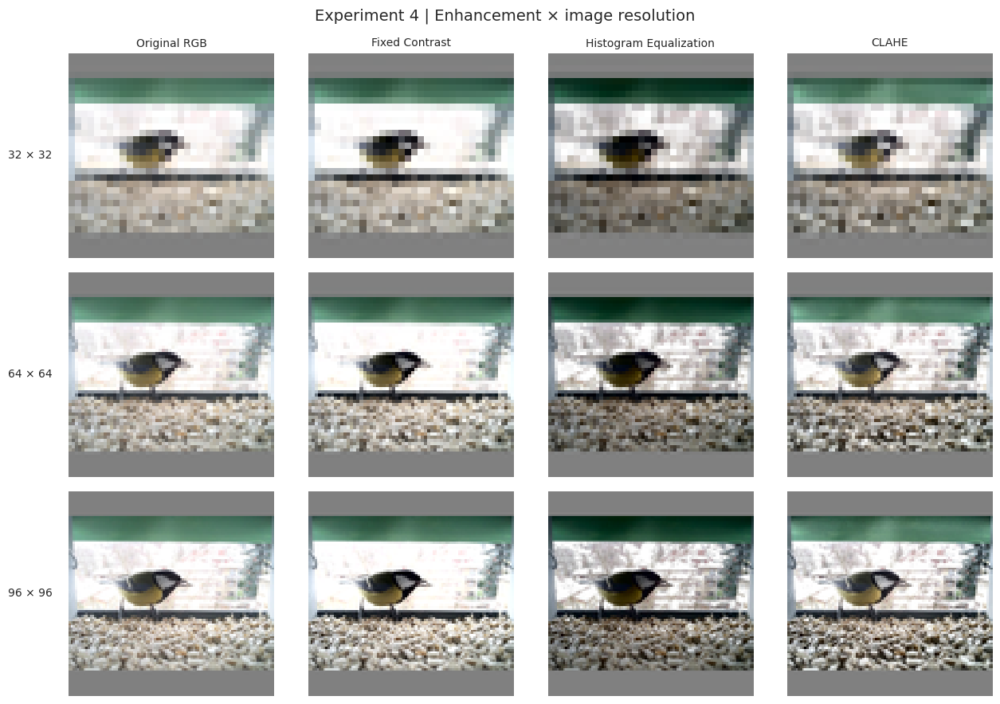


Pixel differences from Original RGB:
 size                 method  mean_absolute_pixel_difference
   32         Fixed Contrast                          0.0257
   32 Histogram Equalization                          0.1584
   32                  CLAHE                          0.0669
   64         Fixed Contrast                          0.0291
   64 Histogram Equalization                          0.1583
   64                  CLAHE                          0.0674
   96         Fixed Contrast                          0.0305
   96 Histogram Equalization                          0.1583
   96                  CLAHE                          0.0680


In [ ]:
# --- Experiment settings --------------------------------------------
R4_SIZES = (32, 64, 96)
R4_K = 4

R4_METHODS = (
    "Original RGB",
    "Fixed Contrast",
    "Histogram Equalization",
    "CLAHE"
)

R4_CONTRAST = 1.3
R4_CLAHE_CLIP = 2.0
R4_CLAHE_GRID = (8, 8)

# --- Image enhancement ----------------------------------------------
def r4_enhance(im, method):

    im = im.convert("RGB")

    if method == "Original RGB":
        return im

    rgb = np.asarray(im, dtype=np.uint8)
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)

    L, A, B = cv2.split(lab)

    if method == "Fixed Contrast":

        mean_L = L.mean()
        L = np.clip(
            (L.astype(np.float32) - mean_L)
            * R4_CONTRAST + mean_L,
            0, 255
        ).astype(np.uint8)

    elif method == "Histogram Equalization":
        L = cv2.equalizeHist(L)

    elif method == "CLAHE":
        clahe = cv2.createCLAHE(
            clipLimit=R4_CLAHE_CLIP,
            tileGridSize=R4_CLAHE_GRID
        )
        L = clahe.apply(L)

    else:
        raise ValueError(f"Unknown method: {method}")

    enhanced_lab = cv2.merge((L, A, B))

    enhanced_rgb = cv2.cvtColor(
        enhanced_lab, cv2.COLOR_LAB2RGB
    )

    return Image.fromarray(enhanced_rgb)


# --- Pad image to square --------------------------------------------
def r4_pad(im):

    s = max(im.size)

    canvas = Image.new(
        "RGB", (s, s), (128, 128, 128)
    )

    canvas.paste(
        im,
        (
            (s - im.width) // 2,
            (s - im.height) // 2
        )
    )

    return canvas


# --- Complete preprocessing pipeline --------------------------------
def r4_load_img(fname, method, size):

    with Image.open(IMG_DIR / fname) as im:

        enhanced = r4_enhance(im, method)
        canvas = r4_pad(enhanced)

        resized = canvas.resize(
            (size, size),
            Image.Resampling.LANCZOS
        )

        return (
            np.asarray(resized, dtype=np.float32)
            / 255.0
        )


# --- Visual comparison ----------------------------------------------
# Use a Great Tit photograph as an example
sample_file = train_df.loc[
    train_df["species"] == "Parus major", "file"
].iloc[0]

fig, axs = plt.subplots(
    len(R4_SIZES),
    len(R4_METHODS),
    figsize=(13, 9)
)

for i, size in enumerate(R4_SIZES):

    for j, method in enumerate(R4_METHODS):

        img = r4_load_img(
            sample_file, method, size
        )

        axs[i, j].imshow(
            img,
            interpolation="nearest"
        )
        axs[i, j].axis("off")

        if i == 0:
            axs[i, j].set_title(
                method, fontsize=10
            )

        if j == 0:
            axs[i, j].text(-0.08,0.5,f"{size} × {size}",ha="right",va="center",transform=axs[i,j].transAxes,fontsize=10)

plt.suptitle(
    "Experiment 4 | Enhancement × image resolution",
    fontsize=14
)

plt.tight_layout()
plt.show()


# --- Quantify changes in pixel values -------------------------------
preview_rows = []

for size in R4_SIZES:

    original = r4_load_img(
        sample_file, "Original RGB", size
    )

    for method in R4_METHODS[1:]:

        enhanced = r4_load_img(
            sample_file, method, size
        )

        mean_difference = np.mean(
            np.abs(enhanced - original)
        )

        preview_rows.append({
            "size": size,
            "method": method,
            "mean_absolute_pixel_difference": mean_difference
        })

r4_preview = pd.DataFrame(preview_rows)

print("\nPixel differences from Original RGB:")
print(r4_preview.round(4).to_string(index=False))

### 6.4.3 CNN training and cross-validation

All 12 configurations use the same network design and training protocol, with the input size varied as specified. The five grouped assessment folds and two training seeds are identical to those used in Experiments 1–3. One fold is assessed, the next is used for early stopping, and the remaining three fit the network. The full factorial comparison comprises **3 resolutions × 4 enhancement methods × 5 folds × 2 seeds = 120 CNN fits**. Parameter counts are recorded for each input size to document the architecture–resolution relationship.

In [ ]:

# --- Experimental settings ------------------------------------------
R4_TEST_FOLDS = tuple(range(5))
R4_SEEDS = (0, 1)


# --- Prepare metadata ------------------------------------------------
r4_sub = train_df[
    train_df["species"].isin(SPECIES[:R4_K])
].reset_index(drop=True)

r4_y = r4_sub["species"].map(
    {sp: i for i, sp in enumerate(SPECIES[:R4_K])}
).to_numpy()

r4_fold = r4_sub["fold"].to_numpy()
r4_indices = np.arange(len(r4_sub))
r4_files = r4_sub["file"].tolist()

# --- CNN architecture ------------------------------------------------
def r4_build_cnn(size):

    model = keras.Sequential()

    model.add(
        layers.Input(shape=(size, size, 3))
    )

    # Same geometric augmentation as before
    model.add(layers.RandomFlip("horizontal"))
    model.add(layers.RandomTranslation(0.1, 0.1))

    # Four convolutional blocks
    for k, filters in enumerate((32, 64, 128, 128)):

        model.add(
            layers.Conv2D(
                filters, (3, 3), padding="same"
            )
        )
        model.add(
            layers.LeakyReLU(negative_slope=0.1)
        )
        model.add(layers.MaxPooling2D((2, 2)))

        model.add(
            layers.Dropout(
                0.25 if k < 3 else 0.5
            )
        )

    model.add(layers.Flatten())
    model.add(layers.Dense(128))
    model.add(
        layers.LeakyReLU(negative_slope=0.1)
    )
    model.add(layers.Dropout(0.3))

    model.add(
        layers.Dense(R4_K, activation="softmax")
    )

    model.compile(
        optimizer=keras.optimizers.Adam(1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


# --- Prepare one enhancement method at a time ------------------------
def r4_prepare_images(method):

    arrays = {
        size: np.empty(
            (len(r4_files), size, size, 3),
            dtype=np.float32
        )
        for size in R4_SIZES
    }

    for i, fname in enumerate(r4_files):

        with Image.open(IMG_DIR / fname) as im:

            enhanced = r4_enhance(im, method)
            canvas = r4_pad(enhanced)

            for size in R4_SIZES:

                resized = canvas.resize(
                    (size, size),
                    Image.Resampling.LANCZOS
                )

                arrays[size][i] = (
                    np.asarray(resized, dtype=np.float32)
                    / 255.0
                )

        if (i + 1) % 500 == 0:
            print(
                f"  Prepared {i + 1}/{len(r4_files)} images"
            )

    return arrays


# --- Train and evaluate ----------------------------------------------
r4_rows = []
r4_predictions = []

for method in R4_METHODS:

    print(f"\nPreparing images: {method}")

    images_by_size = r4_prepare_images(method)

    for size in R4_SIZES:

        X = images_by_size[size]

        print(f"\nResolution: {size}x{size} | {method}")

        for test_fold in R4_TEST_FOLDS:

            te = r4_indices[
                r4_fold == test_fold
            ]

            va = r4_indices[
                r4_fold == (test_fold + 1) % 5
            ]

            tr = r4_indices[
                ~np.isin(
                    r4_fold,
                    [test_fold, (test_fold + 1) % 5]
                )
            ]

            assert len(tr) and len(va) and len(te)

            for seed in R4_SEEDS:

                keras.backend.clear_session()
                keras.utils.set_random_seed(seed)

                model = r4_build_cnn(size)

                n_params = model.count_params()

                early_stop = keras.callbacks.EarlyStopping(
                    monitor="val_loss",
                    patience=8,
                    restore_best_weights=True
                )

                t0 = time.time()

                history = model.fit(
                    X[tr],
                    r4_y[tr],
                    batch_size=50,
                    epochs=50,
                    validation_data=(
                        X[va],
                        r4_y[va]
                    ),
                    callbacks=[early_stop],
                    verbose=0
                )

                pred = model.predict(
                    X[te], verbose=0
                ).argmax(axis=1)

                macro_f1 = f1_score(
                    r4_y[te],
                    pred,
                    average="macro",
                    labels=list(range(R4_K)),
                    zero_division=0
                )

                bal_acc = balanced_accuracy_score(
                    r4_y[te], pred
                )

                r4_rows.append({
                    "size": size,
                    "method": method,
                    "fold": test_fold,
                    "seed": seed,
                    "macro_f1": macro_f1,
                    "balanced_accuracy": bal_acc,
                    "epochs": len(history.history["loss"]),
                    "parameters": n_params,
                    "time_seconds": time.time() - t0
                })

                r4_predictions.append({
                    "size": size,
                    "method": method,
                    "fold": test_fold,
                    "seed": seed,
                    "indices": te.copy(),
                    "pred": pred.copy()
                })

                print(
                    f"{size:3d}px | {method:24s} | "
                    f"Fold {test_fold} | Seed {seed} | "
                    f"F1 = {macro_f1:.3f} | "
                    f"Epochs = {len(history.history['loss'])}"
                )

                # Save progress after each fit
                pd.DataFrame(r4_rows).to_csv(
                    "experiment4_results.csv",
                    index=False
                )

                del model, history
                gc.collect()

    # Release images before loading next method
    del images_by_size, X
    gc.collect()

# --- Results ---------------------------------------------------------
r4_results = pd.DataFrame(r4_rows)

print("\nExperiment 4 completed!")
print("Training runs:", len(r4_results))

print("\nModel parameter counts:")
print(
    r4_results.groupby("size")["parameters"].first()
)



Preparing images: Original RGB
  Prepared 500/1591 images
  Prepared 1000/1591 images
  Prepared 1500/1591 images

Resolution: 32x32 | Original RGB
 32px | Original RGB             | Fold 0 | Seed 0 | F1 = 0.514 | Epochs = 33
 32px | Original RGB             | Fold 0 | Seed 1 | F1 = 0.506 | Epochs = 41
 32px | Original RGB             | Fold 1 | Seed 0 | F1 = 0.450 | Epochs = 29
 32px | Original RGB             | Fold 1 | Seed 1 | F1 = 0.515 | Epochs = 34
 32px | Original RGB             | Fold 2 | Seed 0 | F1 = 0.569 | Epochs = 50
 32px | Original RGB             | Fold 2 | Seed 1 | F1 = 0.514 | Epochs = 31
 32px | Original RGB             | Fold 3 | Seed 0 | F1 = 0.598 | Epochs = 50
 32px | Original RGB             | Fold 3 | Seed 1 | F1 = 0.575 | Epochs = 41
 32px | Original RGB             | Fold 4 | Seed 0 | F1 = 0.611 | Epochs = 35
 32px | Original RGB             | Fold 4 | Seed 1 | F1 = 0.584 | Epochs = 50

Resolution: 64x64 | Original RGB
 64px | Original RGB             | Fo

### 6.4.4 Results and visualisation

The first graph compares mean macro-F1 (± SD) for each enhancement method across the three resolutions. To isolate enhancement effects, the second graph shows the matched gain over Original RGB **at the same resolution**. The third graph quantifies an interaction-like contrast: the change in enhancement gain at 64 or 96 pixels relative to its gain at 32 pixels. Species-level heatmaps show how the methods affect the four classes at each resolution.

Let $R_{s,m,f,r}$ denote macro-F1 at resolution $s$, method $m$, assessment fold $f$ and seed $r$. The paired enhancement gain and the contrast with 32 pixels are

$$
\Delta_{s,m,f,r}=R_{s,m,f,r}-R_{s,\mathrm{RGB},f,r},
\qquad
I_{s,32,m,f,r}=\Delta_{s,m,f,r}-\Delta_{32,m,f,r}.
$$

Positive values of $\Delta$ represent improvement over the same-size RGB reference; positive $I$ values indicate that the enhancement gain is greater than at 32 pixels. These quantities are descriptive comparisons of fitted networks, not estimates of causal effects or formal significance tests.


Experiment 4 | Summary (all 120 fits):
 size                 method  mean_f1  sd_f1  mean_bal_acc  mean_epochs  runs
   32                  CLAHE    0.503  0.092         0.526         38.2    10
   32         Fixed Contrast    0.471  0.129         0.503         31.0    10
   32 Histogram Equalization    0.515  0.058         0.534         37.8    10
   32           Original RGB    0.544  0.051         0.555         39.4    10
   64                  CLAHE    0.533  0.097         0.555         36.7    10
   64         Fixed Contrast    0.549  0.039         0.560         31.4    10
   64 Histogram Equalization    0.547  0.062         0.559         33.7    10
   64           Original RGB    0.501  0.163         0.529         32.0    10
   96                  CLAHE    0.542  0.100         0.562         37.4    10
   96         Fixed Contrast    0.537  0.104         0.551         33.2    10
   96 Histogram Equalization    0.563  0.056         0.574         34.2    10
   96           Original 

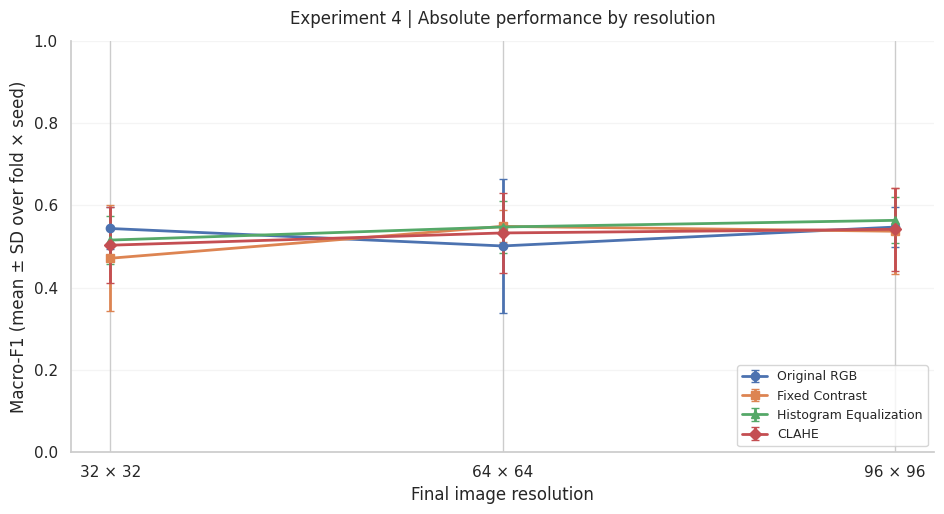


Mean paired enhancement gain at each resolution:
method  Fixed Contrast  Histogram Equalization  CLAHE
size                                                 
32              -0.072                  -0.028 -0.041
64               0.048                   0.046  0.032
96              -0.010                   0.016 -0.005


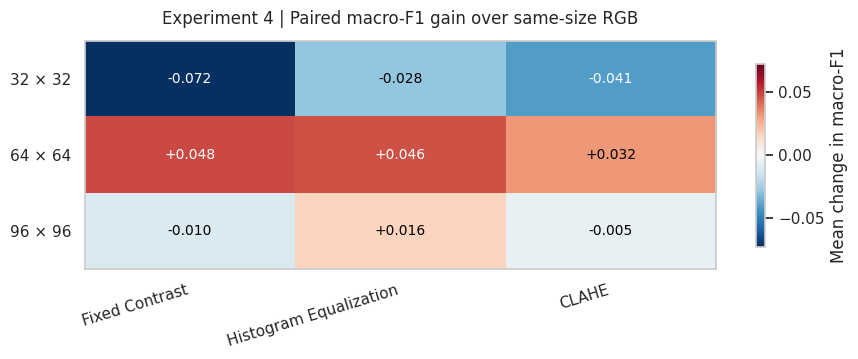


Interaction: difference in gain relative to 32 × 32:
 size                 method  mean    sd
   64                  CLAHE 0.072 0.178
   64         Fixed Contrast 0.120 0.219
   64 Histogram Equalization 0.074 0.143
   96                  CLAHE 0.035 0.120
   96         Fixed Contrast 0.062 0.168
   96 Histogram Equalization 0.044 0.076


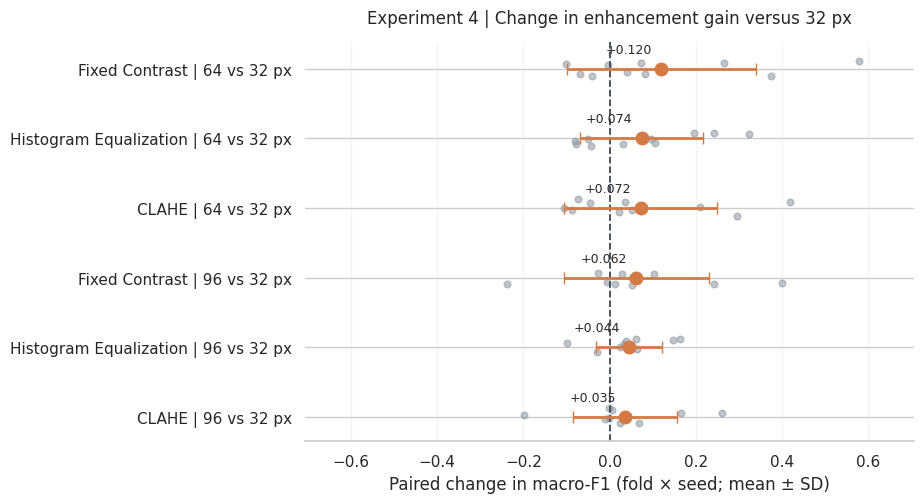


Descriptive best mean macro-F1 setting at each resolution:
  32 × 32: Original RGB (mean 0.544)
  64 × 64: Fixed Contrast (mean 0.549)
  96 × 96: Histogram Equalization (mean 0.563)
Compare these with the paired-gain figure; small differences may be unstable.


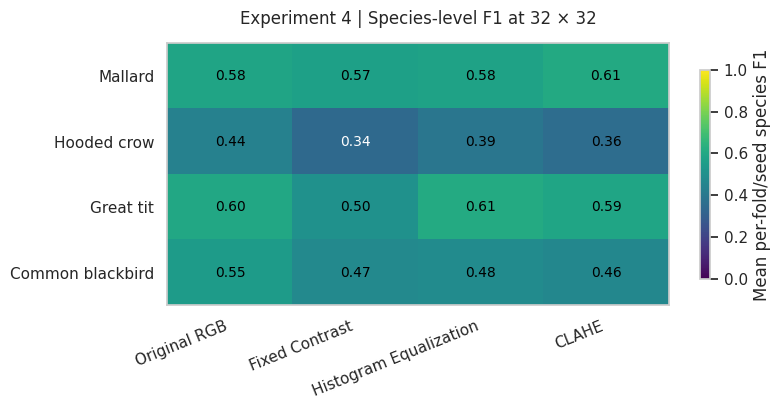

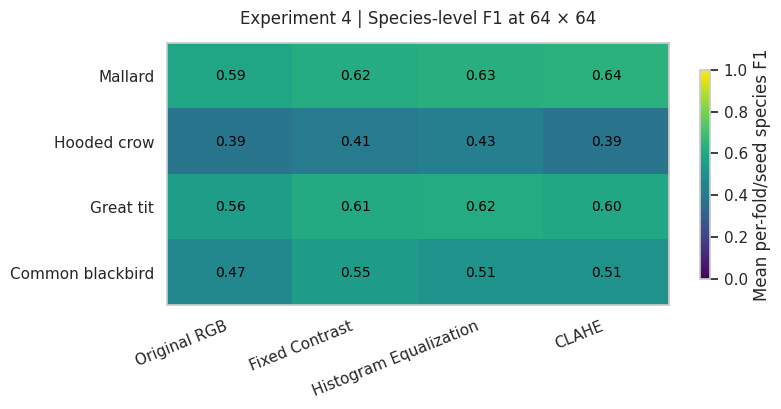

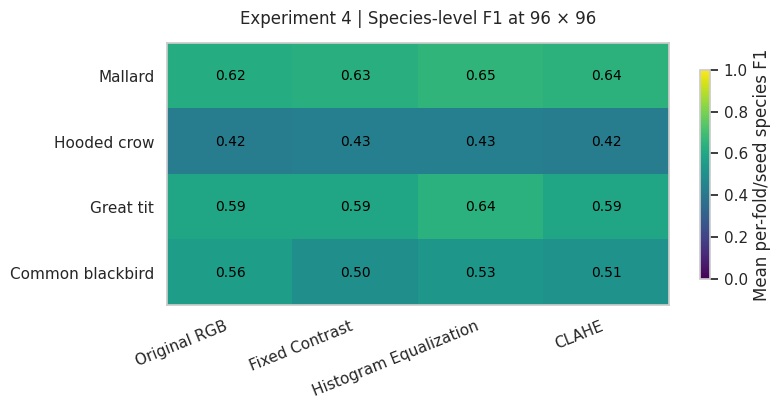


All experiment-4 figures and tables saved in /content/experiment_outputs


In [ ]:

# Experiment 4: verify that the complete 3×4×5×2 design has finished.
required_index=pd.MultiIndex.from_product(
    [R4_SIZES,R4_METHODS,R4_TEST_FOLDS,R4_SEEDS],
    names=["size","method","fold","seed"])
actual_index=pd.MultiIndex.from_frame(
    r4_results[["size","method","fold","seed"]])
if (len(r4_results)!=len(required_index)
        or actual_index.has_duplicates
        or not actual_index.sort_values().equals(required_index.sort_values())):
    raise RuntimeError(
        f"Experiment 4 incomplete or duplicated: {len(r4_results)}/"
        f"{len(required_index)} runs. Finish/resume training before analysing."
    )

r4_summary=(r4_results.groupby(["size","method"])
    .agg(mean_f1=("macro_f1","mean"),sd_f1=("macro_f1","std"),
         mean_bal_acc=("balanced_accuracy","mean"),
         mean_epochs=("epochs","mean"),runs=("macro_f1","size"))
    .reset_index())
print("Experiment 4 | Summary (all 120 fits):")
print(r4_summary.round(3).to_string(index=False))

# Absolute F1 with descriptive SD; RGB reference and other methods at each size.
fig,ax=plt.subplots(figsize=(9.6,5.3))
for i,method in enumerate(R4_METHODS):
    rows=r4_summary[r4_summary["method"]==method].set_index("size").reindex(R4_SIZES)
    ax.errorbar(R4_SIZES,rows["mean_f1"],yerr=rows["sd_f1"],
       label=method,marker=['o','s','^','D'][i],markersize=6,
       linewidth=2,capsize=3)
ax.set_xticks(R4_SIZES,[f"{v} × {v}" for v in R4_SIZES])
ax.set_xlabel("Final image resolution")
ax.set_ylabel("Macro-F1 (mean ± SD over fold × seed)")
ax.set_ylim(0,1)
ax.set_title("Experiment 4 | Absolute performance by resolution",pad=12)
ax.legend(loc="lower right",fontsize=9,frameon=True)
ax.grid(axis="y",alpha=.2)
ax.spines[['top','right']].set_visible(False)
fig.tight_layout()
fig.savefig(EXP_OUT/"exp4_performance.png",dpi=180,bbox_inches='tight')
plt.show()

# Match fold + seed within each size, THEN compare enhancement gains across sizes.
r4_paired=r4_results.pivot(index=["size","fold","seed"],
                          columns="method",values="macro_f1")
r4_gains=r4_paired[list(R4_METHODS[1:])].sub(r4_paired["Original RGB"],axis=0)
r4_gain_mean=r4_gains.groupby(level="size").mean().reindex(index=R4_SIZES,
                            columns=R4_METHODS[1:])
print("\nMean paired enhancement gain at each resolution:")
print(r4_gain_mean.round(3).to_string())

# Diverging heatmap: neutral zero is always the midpoint.
mat=r4_gain_mean.to_numpy(dtype=float)
lim=max(.01,float(np.nanmax(np.abs(mat))))
fig,ax=plt.subplots(figsize=(9,3.75))
im=ax.imshow(mat,cmap="RdBu_r",vmin=-lim,vmax=lim,aspect="auto")
ax.set_xticks(range(len(R4_METHODS)-1),R4_METHODS[1:],rotation=17,ha='right')
ax.set_yticks(range(len(R4_SIZES)),[f"{v} × {v}" for v in R4_SIZES])
ax.grid(False, which="both")
for (i,j),value in np.ndenumerate(mat):
    ax.text(j,i,f"{value:+.3f}",ha='center',va='center',
            fontsize=10,color='white' if abs(value)>.56*lim else 'black')
ax.set_title("Experiment 4 | Paired macro-F1 gain over same-size RGB",pad=12)
fig.colorbar(im,ax=ax,label='Mean change in macro-F1',shrink=.8)
fig.tight_layout()
fig.savefig(EXP_OUT/"exp4_enhancement_gains.png",dpi=180,bbox_inches='tight')
plt.show()

# Interaction: subtract matched 32px gains (same fold and seed).
r4_interaction_rows=[]
for size in R4_SIZES[1:]:
    for method in R4_METHODS[1:]:
        aligned=(r4_gains.xs(size,level="size")[method]
                 -r4_gains.xs(R4_SIZES[0],level="size")[method])
        for (fold,seed),change in aligned.items():
            r4_interaction_rows.append({"size":size,"method":method,
                                        "fold":fold,"seed":seed,
                                        "interaction":change})
r4_interaction_details=pd.DataFrame(r4_interaction_rows)
r4_interactions=(r4_interaction_details.groupby(["size","method"])["interaction"]
                 .agg(mean='mean',sd='std').reset_index())
print("\nInteraction: difference in gain relative to 32 × 32:")
print(r4_interactions.round(3).to_string(index=False))

# Interaction figure: same fold×seed paired gain differences for 64/96 versus 32.
interaction_order=[f"{m} | {s} vs {R4_SIZES[0]} px"
                   for s in R4_SIZES[1:] for m in R4_METHODS[1:]]
r4_interaction_details["comparison"]=(r4_interaction_details["method"]
    + " | " + r4_interaction_details["size"].astype(str)
    + f" vs {R4_SIZES[0]} px")
r4_interaction_wide=r4_interaction_details.pivot(
    index=["fold","seed"],columns="comparison",values="interaction")
exp_plot_deltas(r4_interaction_wide,
    "Experiment 4 | Change in enhancement gain versus 32 px",
    "exp4_interaction_changes.png",order=interaction_order)

print("\nDescriptive best mean macro-F1 setting at each resolution:")
for size in R4_SIZES:
    rows=r4_summary.loc[r4_summary["size"]==size]
    best=rows.loc[rows["mean_f1"].idxmax()]
    print(f"  {size} × {size}: {best['method']} (mean {best['mean_f1']:.3f})")
print("Compare these with the paired-gain figure; small differences may be unstable.")

# One panel per size for species scores (both seeds included).
r4_species_df=exp_species_f1(r4_predictions,r4_y,["size","method"])
if len(r4_predictions)!=len(required_index):
    raise RuntimeError("Missing predictions for some completed fits; rerun training to create them.")
r4_species_table=(r4_species_df.groupby(["size","species","method"])["f1"]
                  .mean().unstack("method"))
for size in R4_SIZES:
    tab=r4_species_table.loc[size].reindex(index=SPECIES[:R4_K],columns=R4_METHODS)
    exp_plot_species(tab,f"Experiment 4 | Species-level F1 at {size} × {size}",
                     f"exp4_species_f1_{size}px.png")

r4_summary.to_csv(EXP_OUT/"exp4_summary.csv",index=False)
r4_gains.reset_index().to_csv(EXP_OUT/"exp4_paired_gains.csv",index=False)
r4_interaction_details.to_csv(EXP_OUT/"exp4_interaction_by_run.csv",index=False)
r4_interactions.to_csv(EXP_OUT/"exp4_interaction_summary.csv",index=False)
r4_species_df.to_csv(EXP_OUT/"exp4_species_f1_by_run.csv",index=False)
print("\nAll experiment-4 figures and tables saved in", EXP_OUT.resolve())


### 6.4.5 Discussion and limitations

Input resolution did **not** produce a monotonic improvement for the unenhanced **Original RGB** model: mean macro-F1 was **0.544 ± 0.051** at **32 × 32**, **0.501 ± 0.163** at **64 × 64**, and **0.547 ± 0.049** at **96 × 96**. The 64-pixel RGB condition was particularly variable across folds and seeds. Across all **12** resolution–method combinations, **96 × 96 Histogram Equalization** achieved the highest mean macro-F1 (**0.563 ± 0.056**). At 64 pixels, **Fixed Contrast** (**0.549 ± 0.039**) and **Histogram Equalization** (**0.547 ± 0.062**) were close.

The paired gains, each measured against **Original RGB at the same resolution**, depended strongly on image size. At **32 × 32**, all enhancements had negative mean gains: **−0.072** for Fixed Contrast, **−0.028** for Histogram Equalization and **−0.041** for CLAHE. At **64 × 64**, the corresponding gains became **+0.048**, **+0.046** and **+0.032**. At **96 × 96**, they were **−0.010**, **+0.016** and **−0.005**. The interaction-like contrasts relative to 32 pixels also changed: for Histogram Equalization, the difference in gain was **+0.074** at 64 pixels and **+0.044** at 96 pixels. This pattern indicates that enhancement performance cannot be considered independently of resolution.

The **96 × 96 Histogram Equalization** configuration was selected for the held-out test because it had the highest mean CV macro-F1 among the eligible Experiment 4 configurations. However, its mean gain over 96-pixel RGB was only **+0.016**, and variation across folds and seeds remains important. Furthermore, increasing resolution also increased the number of trainable parameters from **307,012** at 32 pixels to **503,620** at 64 pixels and **831,300** at 96 pixels, owing to the `Flatten` layer. Hence the observed differences cannot be attributed solely to extra image detail. The paired gains and interaction-like contrasts are descriptive, not evidence of a causal effect or a statistically established improvement.

# 7. Evaluation on the Independent Held-Out Test Set

Experiments 1–4 were carried out using photographer-grouped cross-validation on the training subset only. We now evaluate five configurations selected according to the training-only CV results on the 597 held-out photographs. The held-out photographers do not overlap with those in the training subset. The configurations in this section were selected using cross-validation scores rather than test-set performance.

The reference is the **32 × 32 Original RGB CNN (M0)**. The four alternatives represent a different question from each experiment:

- **M1 (Experiment 1):** matched **Grayscale at 32 × 32**, the sole matched non-RGB representation, even though RGB had the higher CV mean.
- **M2 (Experiment 2):** **RGB at 32 × 32 with Brightness + Contrast augmentation**, the highest-scoring added colour-augmentation policy.
- **M3 (Experiment 3):** **Histogram Equalization at 32 × 32**, the highest-scoring *enhancement alternative*. **Original RGB remained the overall winner within Experiment 3**, so M3 tests whether the best non-baseline enhancement generalizes.
- **M4 (Experiment 4):** **Histogram Equalization at 96 × 96**, the highest-scoring eligible resolution–method combination, excluding the 32-pixel Original RGB baseline.

The selection code verifies completion of the fold–seed results and avoids evaluating duplicate configurations more than once. All selected models are assessed on the **same independent held-out set**, with macro-F1 as the primary measure and accuracy, balanced accuracy, species-level F1 and confusion matrices as supporting summaries. Held-out results are reported for every selected candidate and are **not used for further tuning or reselection**.

## 7.1 Configuration selection from cross-validation

The table below gives the training-only grouped-CV mean macro-F1 used for the five selected configurations: **M0: 0.544**, **M1: 0.532**, **M2: 0.546**, **M3: 0.515** and **M4: 0.563**. These development scores define the candidates; they are not estimates of the test performance of the separately refitted final models.

In [ ]:
# Select configurations using CV results only; never read test-set performance here.


# Allow results to be loaded from the experiment CSVs in a fresh Colab session.
def final_cv_results(var_name, filename):
    if var_name in globals() and isinstance(globals()[var_name], pd.DataFrame):
        return globals()[var_name].copy()
    path = Path(filename)
    if not path.exists():
        raise FileNotFoundError(
            f"{filename} is missing. Run its experiment first or restore the CV results CSV."
        )
    return pd.read_csv(path)

gs_cv = final_cv_results("gs_results", "grayscale_comparison.csv")
ca_cv = final_cv_results("ca_results", "colour_augmentation_results.csv")
eh_cv = final_cv_results("eh_results", "image_enhancement_results.csv")
r4_cv = final_cv_results("r4_results", "experiment4_results.csv")

EXPECTED_FOLDS = set(range(5))
EXPECTED_SEEDS = {0, 1}

def final_verify_cv(df, conditions, keys, experiment):
    """Refuse to select candidates from incomplete or duplicated CV runs."""
    got = list(df[keys + ["fold", "seed"]].itertuples(index=False, name=None))
    expected = {tuple(condition if isinstance(condition, tuple) else (condition,)) + (f, seed)
                for condition in conditions for f in EXPECTED_FOLDS for seed in EXPECTED_SEEDS}
    if len(got) != len(expected) or set(got) != expected:
        raise ValueError(f"{experiment}: expected {len(expected)} unique CV results; found {len(got)} rows.")

final_verify_cv(gs_cv, [(a,b) for a in ("RGB","Grayscale") for b in ("RGB","Grayscale")],
                ["train","test"], "Experiment 1")
final_verify_cv(ca_cv, list(CA_CONFIGS), ["setting"], "Experiment 2")
final_verify_cv(eh_cv, list(EH_CONFIGS), ["method"], "Experiment 3")
final_verify_cv(r4_cv, [(sz, m) for sz in R4_SIZES for m in R4_METHODS],
                ["size","method"], "Experiment 4")

# Experiment 1's sole matched, non-baseline representation is grayscale.
selected_colour = "Grayscale"
selected_aug = (ca_cv.groupby("setting")["macro_f1"].mean()
                .reindex(CA_CONFIGS[1:]).idxmax())
selected_enh = (eh_cv.groupby("method")["macro_f1"].mean()
                .reindex(EH_CONFIGS[1:]).idxmax())

# All resolution×method pairs except the fixed 32-pixel Original RGB baseline.
r4_candidates = (r4_cv.groupby(["size", "method"])["macro_f1"]
                 .mean().reset_index(name="mean_f1"))
r4_candidates = r4_candidates.loc[
    ~((r4_candidates["size"] == 32) &
      (r4_candidates["method"] == "Original RGB"))
]
r4_candidates = r4_candidates.sort_values(
    ["mean_f1", "size", "method"], ascending=[False, True, True],
    kind="stable"
)
selected_size = int(r4_candidates.iloc[0]["size"])
selected_method = str(r4_candidates.iloc[0]["method"])

chosen_rows = [
    {"source": "Baseline", "size":32, "method":"Original RGB", "colour_aug":"Baseline",
     "cv_f1":float(r4_cv.loc[(r4_cv["size"]==32) &
                          (r4_cv["method"]=="Original RGB"),"macro_f1"].mean())},
    {"source": "Experiment 1", "size":32, "method":"Grayscale", "colour_aug":"Baseline",
     "cv_f1":float(gs_cv.loc[(gs_cv["train"]=="Grayscale") &
                           (gs_cv["test"]=="Grayscale"),"macro_f1"].mean())},
    {"source": "Experiment 2", "size":32, "method":"Original RGB", "colour_aug":selected_aug,
     "cv_f1":float(ca_cv.loc[ca_cv["setting"]==selected_aug,"macro_f1"].mean())},
    {"source": "Experiment 3", "size":32, "method":selected_enh, "colour_aug":"Baseline",
     "cv_f1":float(eh_cv.loc[eh_cv["method"]==selected_enh,"macro_f1"].mean())},
    {"source": "Experiment 4", "size":selected_size, "method":selected_method, "colour_aug":"Baseline",
     "cv_f1":float(r4_candidates.iloc[0]["mean_f1"])},
]

# If two experiments select exactly the same preprocessing configuration,
# evaluate it only once and keep a record of both origins.
unique_configs = {}
for row in chosen_rows:
    key = (row["size"], row["method"], row["colour_aug"])
    if key not in unique_configs:
        unique_configs[key] = {**row, "sources":[row["source"]]}
    else:
        unique_configs[key]["sources"].append(row["source"])

final_configs = list(unique_configs.values())
for i, cfg in enumerate(final_configs):
    cfg["id"] = f"M{i}"
    cfg["label"] = ("Baseline" if cfg["source"] == "Baseline" else
        f"{cfg['source']}: {cfg['method'] if cfg['method'] != 'Original RGB' else 'RGB'}"
        + (f" + {cfg['colour_aug']}" if cfg["colour_aug"] != "Baseline" else "")
        + f" ({cfg['size']} px)")

selection_table = pd.DataFrame([
    {"Source": ", ".join(c["sources"]), "ID":c["id"],
     "Size": c["size"], "Image representation":c["method"],
     "Training colour augmentation":c["colour_aug"],
     "Selected CV macro-F1":c["cv_f1"]}
    for c in final_configs
])
print("Configurations selected BEFORE test-set evaluation:")
display(selection_table)
EXP_OUT.mkdir(parents=True, exist_ok=True)
selection_table.to_csv(EXP_OUT / "final_test_model_selection.csv", index=False)

Configurations selected BEFORE test-set evaluation:


,Source,ID,Size,Image representation,Training colour augmentation,Selected CV macro-F1
0,Baseline,M0,32,Original RGB,Baseline,0.543654
1,Experiment 1,M1,32,Grayscale,Baseline,0.531830
2,Experiment 2,M2,32,Original RGB,Brightness + Contrast,0.546413
3,Experiment 3,M3,32,Histogram Equalization,Baseline,0.515497
4,Experiment 4,M4,96,Histogram Equalization,Baseline,0.563423


## 7.2 Model refitting without test-set information

All selected configurations use the same four-block CNN and the original optimizer, dropout and geometric-augmentation settings. The only configuration-specific changes are image representation, additional training-time colour augmentation and image resolution.

For each random seed, **one preassigned grouped CV fold from the training subset** is used solely to determine the early-stopping epoch. The network is then **initialized anew and refitted on the entire training subset** for that fixed number of epochs. Only after this refitting is the model evaluated on `test_df`. This procedure uses all available training observations in the final fit without involving test data in early stopping or model selection. Two seeds (0 and 1) are reported to describe training variability.

The selected epochs, test predictions and per-seed evaluation metrics are exported to support reproducibility.


In [ ]:
# Final training, test predictions and reproducible exports.
# Requires model selections from Section 7.1 and the original data split.


assert "test_df" in globals(), "The independent held-out test set is required."
assert len(train_df) and len(test_df)
assert set(train_df["creator"]).isdisjoint(set(test_df["creator"]))
assert set(train_df["species"]) == set(test_df["species"]) == set(SPECIES)
assert train_df["fold"].between(0, 4).all()

# Persist group-aware data assignments separately from the unpartitioned GBIF ZIP.
cv_assignment_manifest = pd.concat([
    train_df[["gbifID", "file", "species", "creator", "fold"]].assign(split="train"),
    test_df[["gbifID", "file", "species", "creator"]].assign(fold=-1, split="test")
], ignore_index=True)
cv_assignment_manifest.to_csv(EXP_OUT / "data_split_manifest.csv", index=False)

FINAL_SEEDS = (0, 1)
FINAL_EPOCH_LIMIT = 50
FINAL_PATIENCE = 8
FINAL_VALIDATION_FOLD = 0  # From training data only; never from test_df.
CLASS_TO_INDEX = {species: idx for idx, species in enumerate(SPECIES)}
final_y_train = train_df["species"].map(CLASS_TO_INDEX).to_numpy(dtype=np.int64)
final_y_test = test_df["species"].map(CLASS_TO_INDEX).to_numpy(dtype=np.int64)
inner_train_idx = np.flatnonzero(train_df["fold"].to_numpy() != FINAL_VALIDATION_FOLD)
inner_val_idx = np.flatnonzero(train_df["fold"].to_numpy() == FINAL_VALIDATION_FOLD)
assert len(inner_train_idx) and len(inner_val_idx)
assert set(train_df.iloc[inner_train_idx]["creator"]).isdisjoint(
       set(train_df.iloc[inner_val_idx]["creator"]))

# Same square padding, enhancement and grayscale conversion as Experiments 1–4.
def final_prepare_images(files, config):
    images = []
    for filename in files:
        array = r4_load_img(filename, config["method"] if config["method"] != "Grayscale"
                               else "Original RGB", config["size"])
        if config["method"] == "Grayscale":
            lum = (.299 * array[..., 0] + .587 * array[..., 1]
                   + .114 * array[..., 2]).astype(np.float32)
            array = np.repeat(lum[..., None], 3, axis=-1)
        images.append(array.astype(np.float32))
    return np.stack(images)

def final_build_cnn(config):
    size = int(config["size"])
    model = keras.Sequential()
    model.add(layers.Input(shape=(size, size, 3)))
    model.add(layers.RandomFlip("horizontal"))
    model.add(layers.RandomTranslation(.1, .1))
    if config["colour_aug"] != "Baseline":
        for transform in ca_colour_layers(config["colour_aug"]):
            model.add(transform)
    for k, n_filters in enumerate((32, 64, 128, 128)):
        model.add(layers.Conv2D(n_filters, 3, padding="same"))
        model.add(layers.LeakyReLU(negative_slope=.1))
        model.add(layers.MaxPooling2D(2))
        model.add(layers.Dropout(.25 if k < 3 else .5))
    model.add(layers.Flatten())
    model.add(layers.Dense(128))
    model.add(layers.LeakyReLU(negative_slope=.1))
    model.add(layers.Dropout(.3))
    model.add(layers.Dense(len(SPECIES), activation="softmax"))
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

final_metric_rows = []
final_prediction_rows = []
final_epochs_rows = []

for config in final_configs:
    print(f"\nRefitting {config['id']}: {config['label']}")
    X_train = final_prepare_images(train_df["file"], config)
    X_test = final_prepare_images(test_df["file"], config)

    for seed in FINAL_SEEDS:
        # Stage 1: select training duration on training-only validation data.
        keras.backend.clear_session()
        keras.utils.set_random_seed(seed)
        candidate = final_build_cnn(config)
        history = candidate.fit(
            X_train[inner_train_idx], final_y_train[inner_train_idx],
            validation_data=(X_train[inner_val_idx], final_y_train[inner_val_idx]),
            epochs=FINAL_EPOCH_LIMIT, batch_size=50, verbose=0,
            callbacks=[keras.callbacks.EarlyStopping(
                monitor="val_loss", patience=FINAL_PATIENCE, restore_best_weights=True)]
        )
        selected_epochs = int(np.argmin(history.history["val_loss"]) + 1)
        del candidate, history
        keras.backend.clear_session()

        # Stage 2: new model, trained on ALL training rows at fixed duration.
        keras.utils.set_random_seed(seed)
        fitted = final_build_cnn(config)
        fitted.fit(X_train, final_y_train, epochs=selected_epochs,
                   batch_size=50, verbose=0)

        # The held-out test is accessed only here, after configuration and fit.
        pred = fitted.predict(X_test, verbose=0).argmax(axis=1)
        metric = {
            "model":config["id"], "label":config["label"], "seed":seed,
            "macro_f1":float(f1_score(final_y_test,pred,average="macro",
                                     labels=range(len(SPECIES)),zero_division=0)),
            "accuracy":float(accuracy_score(final_y_test,pred)),
            "balanced_accuracy":float(balanced_accuracy_score(final_y_test,pred)),
            "epochs":selected_epochs,
        }
        final_metric_rows.append(metric)
        final_epochs_rows.append({"model":config["id"], "seed":seed,
                                  "selected_epochs":selected_epochs})
        for row_idx, (actual, predicted) in enumerate(zip(final_y_test, pred)):
            final_prediction_rows.append({
                "model":config["id"], "seed":seed,
                "gbifID":str(test_df.iloc[row_idx]["gbifID"]),
                "file":test_df.iloc[row_idx]["file"],
                "true_class":int(actual), "pred_class":int(predicted),
                "true_species":SPECIES[actual], "predicted_species":SPECIES[predicted],
            })
        print(f"  seed={seed}: epochs={selected_epochs}, macro-F1={metric['macro_f1']:.3f}, "
              f"accuracy={metric['accuracy']:.3f}")
        del fitted
        keras.backend.clear_session()
        gc.collect()
    del X_train, X_test
    gc.collect()

final_test_metrics = pd.DataFrame(final_metric_rows)
final_test_predictions = pd.DataFrame(final_prediction_rows)
final_test_epochs = pd.DataFrame(final_epochs_rows)
final_test_metrics.to_csv(EXP_OUT / "final_test_metrics_by_seed.csv", index=False)
final_test_predictions.to_csv(EXP_OUT / "final_test_predictions.csv", index=False)
final_test_epochs.to_csv(EXP_OUT / "final_test_selected_epochs.csv", index=False)

print("\nAll final-test evaluations completed. Results exported to", EXP_OUT.resolve())


Refitting M0: Baseline
  seed=0: epochs=34, macro-F1=0.529, accuracy=0.566
  seed=1: epochs=44, macro-F1=0.582, accuracy=0.586

Refitting M1: Experiment 1: Grayscale (32 px)
  seed=0: epochs=38, macro-F1=0.492, accuracy=0.529
  seed=1: epochs=23, macro-F1=0.534, accuracy=0.541

Refitting M2: Experiment 2: RGB + Brightness + Contrast (32 px)
  seed=0: epochs=35, macro-F1=0.518, accuracy=0.548
  seed=1: epochs=50, macro-F1=0.561, accuracy=0.571

Refitting M3: Experiment 3: Histogram Equalization (32 px)
  seed=0: epochs=34, macro-F1=0.502, accuracy=0.518
  seed=1: epochs=23, macro-F1=0.527, accuracy=0.533

Refitting M4: Experiment 4: Histogram Equalization (96 px)
  seed=0: epochs=39, macro-F1=0.623, accuracy=0.637
  seed=1: epochs=34, macro-F1=0.598, accuracy=0.621

All final-test evaluations completed. Results exported to /content/experiment_outputs


## 7.3 Held-out test performance and visualisation

The held-out test set is evaluated using the same fixed species order and the same primary and secondary metrics as the cross-validation experiments. Model-level summaries show mean and standard deviation **across the two training seeds**, not uncertainty arising from independent test samples. Paired test differences compare models on the same photographs for the same training seed.

A common-reference comparison, species-level F1 heatmap and row-normalized confusion matrices provide complementary views of generalization. The confusion matrices show predictions for **seed 0** so that each test photograph contributes once per model; aggregate F1 summaries use both seeds.

Held-out test performance (mean ± SD over two seeds):


,configuration,mean_macro_f1,sd_macro_f1,mean_accuracy,mean_bal_acc
model,,,,,
M0,Baseline,0.556,0.037,0.576,0.564
M1,Experiment 1: Grayscale (32 px),0.513,0.030,0.535,0.522
M2,Experiment 2: RGB + Brightness + Contrast (32 px),0.540,0.031,0.559,0.550
M3,Experiment 3: Histogram Equalization (32 px),0.514,0.018,0.525,0.536
M4,Experiment 4: Histogram Equalization (96 px),0.610,0.018,0.629,0.609



Test macro-F1 changes relative to 32-pixel RGB baseline:


,mean,std
Experiment 1: Grayscale (32 px),-0.043,0.008
Experiment 2: RGB + Brightness + Contrast (32 px),-0.016,0.007
Experiment 3: Histogram Equalization (32 px),-0.042,0.020
Experiment 4: Histogram Equalization (96 px),0.054,0.055


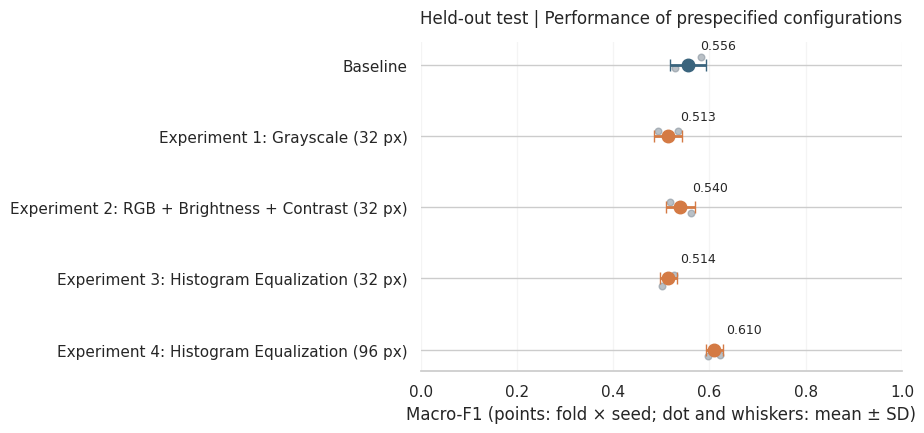

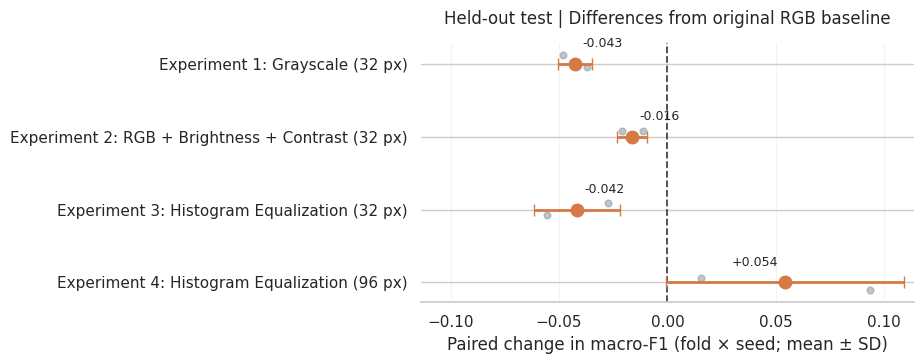

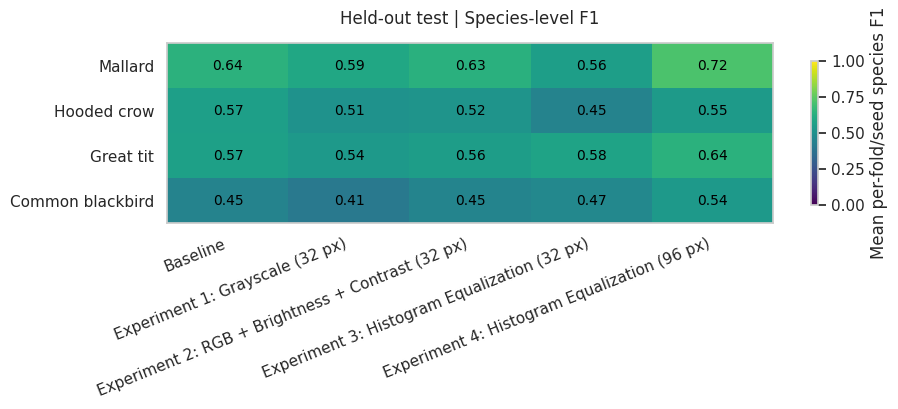

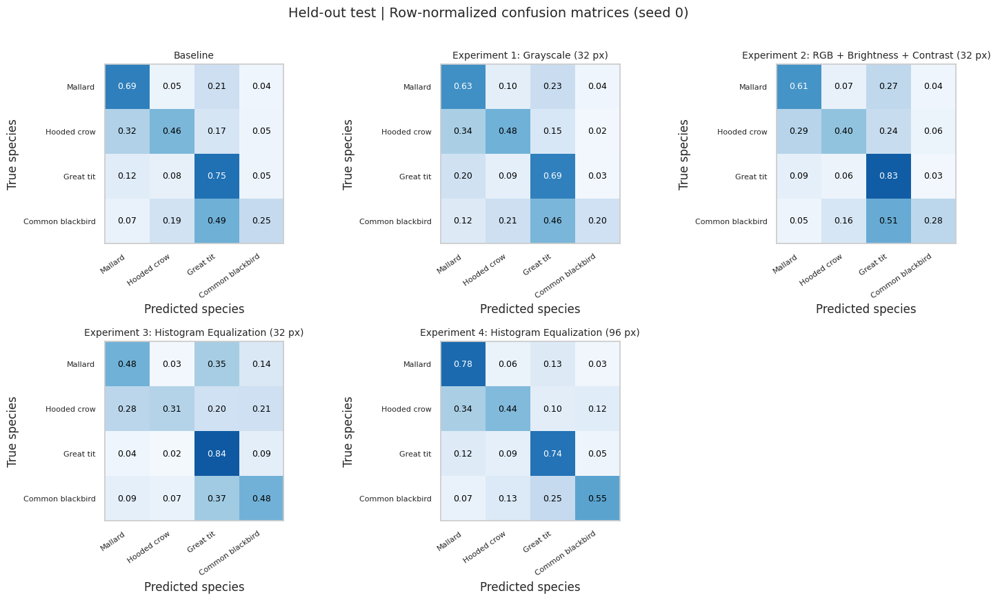

In [ ]:
# Held-out test summaries and consistent final figures.


assert len(final_test_metrics) == len(final_configs) * len(FINAL_SEEDS)
expected_predictions = len(test_df) * len(final_configs) * len(FINAL_SEEDS)
assert len(final_test_predictions) == expected_predictions

model_order = [c["id"] for c in final_configs]
model_labels = {c["id"]:c["label"] for c in final_configs}
summary = (final_test_metrics.groupby("model")
    .agg(mean_macro_f1=("macro_f1","mean"), sd_macro_f1=("macro_f1","std"),
         mean_accuracy=("accuracy","mean"), mean_bal_acc=("balanced_accuracy","mean"))
    .reindex(model_order))
summary.insert(0,"configuration",[model_labels[mid] for mid in model_order])
print("Held-out test performance (mean ± SD over two seeds):")
display(summary.round(3))
summary.to_csv(EXP_OUT / "final_test_summary.csv")

# Pair-by-seed test differences; no tuning or reselection from these scores.
paired_test_f1=final_test_metrics.pivot(index="seed",columns="model",values="macro_f1")
paired_test_differences=paired_test_f1[model_order[1:]].sub(paired_test_f1[model_order[0]],axis=0)
paired_test_differences.columns=[model_labels[m] for m in model_order[1:]]
print("\nTest macro-F1 changes relative to 32-pixel RGB baseline:")
display(paired_test_differences.agg(["mean","std"]).round(3).T)
paired_test_differences.reset_index().to_csv(
    EXP_OUT / "final_test_paired_changes.csv", index=False)

# Overall scores (do not imply confidence intervals from two seeds).
view=final_test_metrics.copy()
view["configuration"] = view["model"].map(model_labels)
exp_plot_scores(view,"configuration",[model_labels[m] for m in model_order],
                "Held-out test | Performance of prespecified configurations",
                "final_test_performance.png")
exp_plot_deltas(paired_test_differences,
                "Held-out test | Differences from original RGB baseline",
                "final_test_differences.png")

# Per-species F1 over seeds, with an explicit fixed species order.
final_species_rows=[]
for (mid, seed), records in final_test_predictions.groupby(["model","seed"]):
    records=records.sort_values("file")
    scores=f1_score(records["true_class"], records["pred_class"],
                    labels=range(len(SPECIES)),average=None,zero_division=0)
    for species, value in zip(SPECIES,scores):
        final_species_rows.append({"model":mid,"seed":seed,"species":species,"f1":value})
final_species_f1=pd.DataFrame(final_species_rows)
species_table=(final_species_f1.groupby(["species","model"])["f1"].mean()
               .unstack("model").reindex(index=SPECIES, columns=model_order))
species_table.columns=[model_labels[m] for m in species_table.columns]
exp_plot_species(species_table, "Held-out test | Species-level F1",
                 "final_test_species_f1.png")
final_species_f1.to_csv(EXP_OUT / "final_test_species_f1_by_seed.csv",index=False)

# Confusion matrices: seed 0 only (no duplicate rows across seeds).
ncols=3
nrows=math.ceil(len(model_order)/ncols)
fig,axes=plt.subplots(nrows,ncols,figsize=(5*ncols,4.3*nrows),squeeze=False)
short_species=[EXP_SHORT_NAMES[s] for s in SPECIES]
for j,mid in enumerate(model_order):
    ax=axes.flat[j]
    rows=final_test_predictions.loc[(final_test_predictions["model"]==mid)
                                     & (final_test_predictions["seed"]==0)]
    cm=confusion_matrix(rows["true_class"],rows["pred_class"],labels=range(len(SPECIES)))
    cm_frac=cm/np.maximum(cm.sum(axis=1,keepdims=True),1)
    ax.imshow(cm_frac,vmin=0,vmax=1,cmap="Blues")
    ax.set_title(model_labels[mid],fontsize=10)
    ax.set_xticks(range(len(SPECIES)), short_species,rotation=35,ha="right",fontsize=8)
    ax.set_yticks(range(len(SPECIES)),short_species,fontsize=8)
    ax.grid(False, which="both")
    ax.set_xlabel("Predicted species")
    ax.set_ylabel("True species")
    for (r,c),rate in np.ndenumerate(cm_frac):
        ax.text(c,r,f"{rate:.2f}",ha="center",va="center",
                color="white" if rate > .55 else "black",fontsize=9)
for j in range(len(model_order), nrows*ncols):
    axes.flat[j].axis("off")
fig.suptitle("Held-out test | Row-normalized confusion matrices (seed 0)",y=1.01,fontsize=14)
fig.tight_layout()
fig.savefig(EXP_OUT / "final_test_confusion_matrices.png",dpi=200,bbox_inches="tight")
plt.show()

## 7.4 Interpretation and limitations

On the **independent held-out test set**, the **32 × 32 Original RGB baseline (M0)** achieved **0.556 ± 0.037** macro-F1 (mean ± SD across two training seeds). The selected alternatives achieved **0.513 ± 0.030** for **Grayscale (M1)**, **0.540 ± 0.031** for **Brightness + Contrast augmentation (M2)**, **0.514 ± 0.018** for **32 × 32 Histogram Equalization (M3)** and **0.610 ± 0.018** for **96 × 96 Histogram Equalization (M4)**. M4 also had the highest mean held-out **accuracy (0.629)** and **balanced accuracy (0.609)**.

Paired by training seed, the mean test macro-F1 changes relative to M0 were **−0.043 ± 0.008** for M1, **−0.016 ± 0.007** for M2, **−0.042 ± 0.020** for M3 and **+0.054 ± 0.055** for M4. Thus, neither removing colour nor the selected 32-pixel augmentation or enhancement method improved the mean held-out macro-F1 compared with the baseline. Although Brightness + Contrast narrowly led the additional augmentation comparison in Experiment 2's CV, its held-out performance was lower than that of M0. Likewise, Histogram Equalization was the best *non-baseline enhancement* in Experiment 3 but did not improve the 32-pixel test score. The **96-pixel Histogram Equalization** model yielded the largest observed test improvement, consistent with its selection in Experiment 4, but the paired improvement varied between the two seeds.

These findings remain **descriptive rather than inferential**. There is only one held-out set and **two training seeds**; the reported SDs quantify variation between those seeds, not confidence intervals for future data. The final networks were trained on the full training subset after their durations had been determined on training-only validation data, whereas the cross-validation models were fitted on three of five folds. Consequently, CV and final test means are not directly interchangeable. Choosing the best of several CV configurations may also make its reported CV mean optimistic. Larger or external held-out samples, additional training seeds, and evaluation in other computing environments would be needed to assess the stability and generalizability of the observed ranking. No candidate was changed or retuned after test-set evaluation.

# Reflection on FAIR Principles

### 1. Findable

**Data:** The dataset is identified by its GBIF occurrence download DOI, which provides a persistent reference to the downloaded records. The metadata contains a unique GBIF occurrence identifier and image filename for each record, along with scientific species names. Each record also includes an image URL, a link to its iNaturalist photo page, creator information, and a recorded licence. These fields support the identification and traceability of individual observations and help users locate the original photographs and assess their reuse conditions.

**Workflow:** The public GitHub repository contains the notebook and README, with a descriptive project title and relevant topic tags. Creating a versioned release or archiving the repository with a persistent identifier, such as a Zenodo DOI, would further improve long-term findability.

### 2. Accessible

**Data:** The occurrence data can be located through GBIF using the download DOI. The image archive is stored separately in Google Drive and is downloaded automatically by the notebook. Its accessibility depends on the continued availability of the file.

**Workflow:** The notebook and documentation are available through GitHub and can be run in Google Colab. This reduces the need for local setup, although users need a suitable internet connection and access to Colab. Local execution may require additional environment and path configuration.

### 3. Interoperable

**Data:** The dataset metadata is stored in CSV format, which can be read by many data-analysis tools. Scientific species names and GBIF identifiers provide standardised ways to interpret and reference observations. Keeping column names clear and consistent, and recording each image's source, creator and licence, makes the dataset easier for others to understand, trace and reuse.

**Workflow:** The project uses Jupyter notebooks and widely adopted Python libraries, including pandas, NumPy, scikit-learn, and TensorFlow/Keras. These tools and formats support integration with other Python-based analysis workflows.

### 4. Reusable

**Data:** The dataset includes only images recorded as CC0, CC BY, or CC BY-SA. However, these licences have different conditions. Retaining each image's licence, creator, and source information is important for attribution and lawful reuse. The GBIF download citation and documented data-preparation steps also support traceability.

**Workflow:** The notebook documents the data preparation, model experiments, and evaluation methods, helping others understand and adapt the analysis. The repository's MIT License covers the original code and documentation, not third-party photographs or source data. Package versions can be recorded to describe the computational environment, although the absence of pinned dependencies means exact reproduction may require additional environment adjustments.